# Trustworthy AI - HW4 - Q2
# Amin Aghakasiri - 810101381

### Step1: Data Preparation

In [ ]:
import json
import random
import math
import gc
import copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import shutil
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    balanced_accuracy_score
)
from opacus import PrivacyEngine
from opacus.accountants import RDPAccountant
from opacus.accountants.utils import get_noise_multiplier
from opacus.utils.batch_memory_manager import BatchMemoryManager
from opacus.validators import ModuleValidator

In [ ]:
SEED = 30
NUM_SILOS = 8
MEMBER_FRACTION = 0.5
MEMBER_TRAIN_FRACTION = 0.5
CACHE_DIR = Path("./femnist_cache")
OUTPUT_DIR = Path("./femnist_prepared")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
POSSIBLE_SILO_COUNTS = np.array([1, 2, 3, 4])
SILO_COUNT_PROBABILITIES = np.array([0.30, 0.40, 0.20, 0.10])
random.seed(SEED)
np.random.seed(SEED)

In [4]:
femnist = load_dataset(
    "flwrlabs/femnist",
    split="train",
    cache_dir=str(CACHE_DIR)
)

README.md:   0%|          | 0.00/6.09k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  201MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/814277 [00:00<?, ? examples/s]

In [ ]:
print(femnist)
print("Dataset features:")
print(femnist.features)

Dataset({
    features: ['image', 'writer_id', 'hsf_id', 'character'],
    num_rows: 814277
})

Dataset features:
{'image': Image(mode=None, decode=True), 'writer_id': Value('string'), 'hsf_id': Value('int64'), 'character': ClassLabel(names=['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z'])}


In [ ]:
writer_ids = np.asarray(femnist["writer_id"])
labels = np.asarray(femnist["character"], dtype=np.int16)
label_feature = femnist.features["character"]
class_names = label_feature.names
num_samples = len(femnist)
num_classes = len(class_names)
unique_subjects = np.unique(writer_ids)
num_subjects = len(unique_subjects)

subject_counts = (
    pd.Series(writer_ids, name="writer_id")
    .value_counts()
    .sort_index()
    .rename("num_samples")
)

print(f"Total number of samples: {num_samples:,}")
print(f"Number of classes: {num_classes}")
print(f"Number of subjects: {num_subjects:,}")
print(f"Image shape: 28 x 28")
print("Number of samples per subject")
print("-" * 50)
print(subject_counts.describe(percentiles=[0.25, 0.50, 0.75]).round(2))
print("Ten subjects from the table:")
print(subject_counts.head(10))

Total number of samples: 814,277
Number of classes: 62
Number of subjects: 3,597
Image shape: 28 x 28

Number of samples per subject
--------------------------------------------------
count    3597.00
mean      226.38
std        88.86
min        18.00
25%       165.00
50%       178.00
75%       306.00
max       583.00
Name: num_samples, dtype: float64

Ten subjects from the table:
writer_id
f0000_14    382
f0001_41    413
f0002_01    404
f0003_42    397
f0004_09    315
f0005_26    351
f0006_12    380
f0007_14    375
f0008_45    418
f0009_06    377
Name: num_samples, dtype: int64


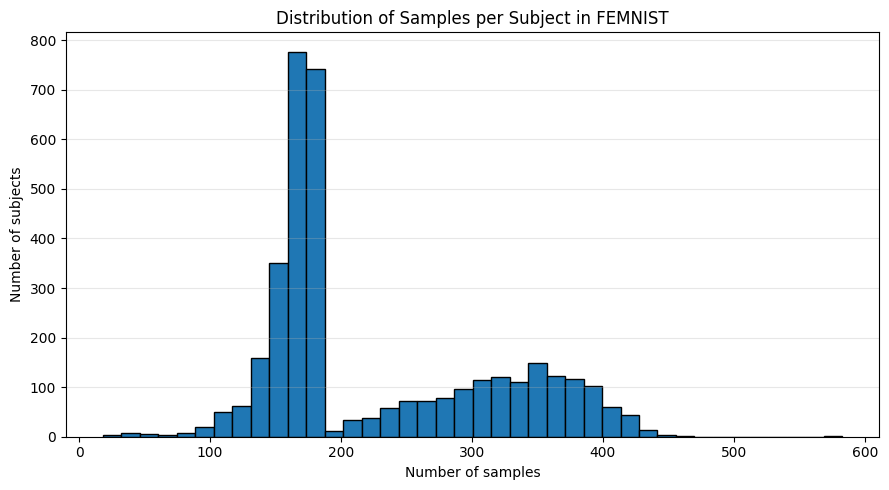

In [9]:
subject_counts.to_csv(
    OUTPUT_DIR / "samples_per_subject.csv",
    header=True
)
plt.figure(figsize=(9, 5))
plt.hist(subject_counts.values, bins=40, edgecolor="black")
plt.xlabel("Number of samples")
plt.ylabel("Number of subjects")
plt.title("Distribution of Samples per Subject in FEMNIST")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

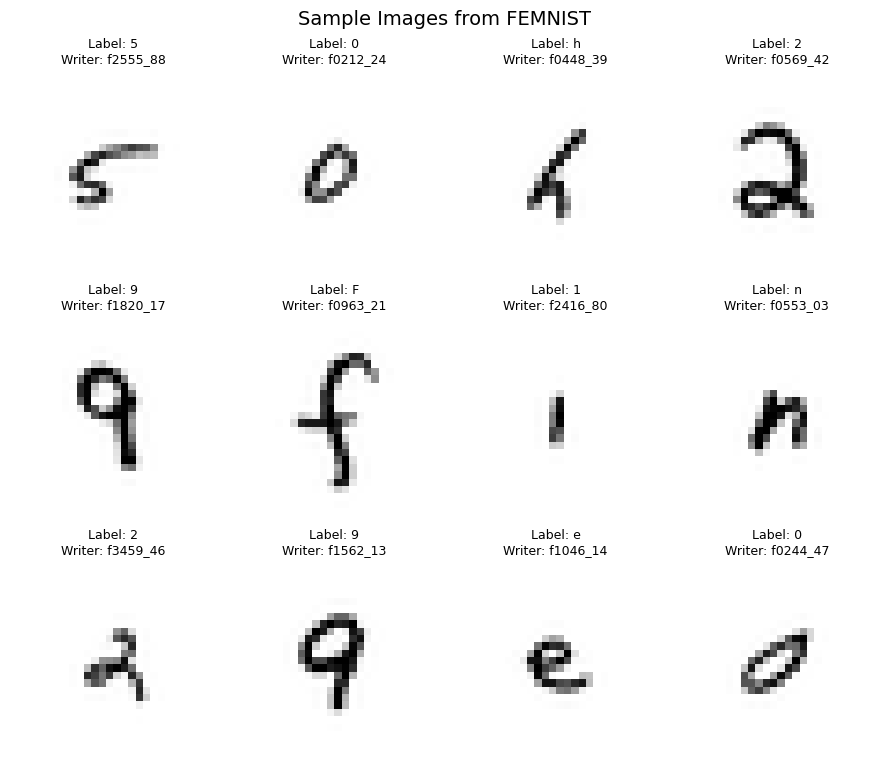

In [10]:
sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(
    num_samples,
    size=12,
    replace=False
)

fig, axes = plt.subplots(3, 4, figsize=(9, 8))
axes = axes.ravel()
for ax, sample_index in zip(axes, sample_indices):
    sample = femnist[int(sample_index)]

    image = np.asarray(sample["image"])
    label = int(sample["character"])
    writer = sample["writer_id"]

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"Label: {class_names[label]}\nWriter: {writer}",
        fontsize=9
    )
    ax.axis("off")
plt.suptitle("Sample Images from FEMNIST", fontsize=14)
plt.tight_layout()
plt.show()

In [11]:
metadata = pd.DataFrame({
    "writer_id": writer_ids
})
subject_to_indices = {}
for subject, indices in metadata.groupby("writer_id").groups.items():
    subject_to_indices[subject] = indices.to_numpy(dtype=np.int64)

In [12]:
split_rng = np.random.default_rng(SEED)
shuffled_subjects = split_rng.permutation(unique_subjects)

num_member_subjects = int(round(MEMBER_FRACTION * num_subjects))
member_subjects = np.sort(shuffled_subjects[:num_member_subjects])
nonmember_subjects = np.sort(shuffled_subjects[num_member_subjects:])

member_subject_set = set(member_subjects.tolist())
nonmember_subject_set = set(nonmember_subjects.tolist())
print(f"Member subjects: {len(member_subjects):,}")
print(f"Non-member subjects: {len(nonmember_subjects):,}")

Member subjects: 1,798
Non-member subjects: 1,799


In [13]:
member_train_by_subject = {}
member_holdout_by_subject = {}
member_train_parts = []
member_holdout_parts = []

for subject in member_subjects:
    indices = subject_to_indices[subject].copy()
    indices = split_rng.permutation(indices)

    split_point = int(
        np.floor(len(indices) * MEMBER_TRAIN_FRACTION)
    )

    split_point = max(1, split_point)

    if split_point == len(indices):
        split_point -= 1

    train_indices = indices[:split_point]
    holdout_indices = indices[split_point:]

    member_train_by_subject[subject] = train_indices
    member_holdout_by_subject[subject] = holdout_indices

    member_train_parts.append(train_indices)
    member_holdout_parts.append(holdout_indices)

member_train_indices = np.concatenate(member_train_parts)
member_holdout_indices = np.concatenate(member_holdout_parts)

nonmember_indices = np.concatenate([
    subject_to_indices[subject]
    for subject in nonmember_subjects
])

member_total_images = (
    len(member_train_indices) +
    len(member_holdout_indices)
)


print(f"Member subjects: {len(member_subjects):,}")
print(f"Non-member subjects: {len(nonmember_subjects):,}")
print(f"All images of Member subjects: {member_total_images:,}")
print(f"Member training images: {len(member_train_indices):,}")
print(f"Member holdout images: {len(member_holdout_indices):,}")
print(f"All Non-member images:  {len(nonmember_indices):,}")

Member subjects: 1,798
Non-member subjects: 1,799
All images of Member subjects: 408,589
Member training images: 203,849
Member holdout images: 204,740
All Non-member images:  405,688


In [14]:
partition_rng = np.random.default_rng(SEED + 2)
silo_parts = [[] for _ in range(NUM_SILOS)]
silo_subjects = [set() for _ in range(NUM_SILOS)]
silo_loads = np.zeros(NUM_SILOS, dtype=np.int64)
subject_silo_map = {}
subject_silo_sample_counts = {}

for subject in member_subjects:
    subject_indices = member_train_by_subject[subject].copy()
    subject_indices = partition_rng.permutation(subject_indices)

    num_subject_silos = int(
        partition_rng.choice(
            POSSIBLE_SILO_COUNTS,
            p=SILO_COUNT_PROBABILITIES
        )
    )

    num_subject_silos = min(
        num_subject_silos,
        len(subject_indices),
        NUM_SILOS
    )

    shuffled_silo_ids = np.arange(NUM_SILOS)
    partition_rng.shuffle(shuffled_silo_ids)

    ordered_silo_ids = sorted(
        shuffled_silo_ids,
        key=lambda silo_id: silo_loads[silo_id]
    )

    selected_silos = ordered_silo_ids[:num_subject_silos]

    subject_parts = np.array_split(
        subject_indices,
        num_subject_silos
    )

    subject_silo_map[subject] = []
    subject_silo_sample_counts[subject] = {}

    for silo_id, part in zip(selected_silos, subject_parts):
        if len(part) == 0:
            continue

        part = np.asarray(part, dtype=np.int64)

        silo_parts[silo_id].append(part)
        silo_subjects[silo_id].add(subject)
        silo_loads[silo_id] += len(part)

        subject_silo_map[subject].append(int(silo_id))
        subject_silo_sample_counts[subject][int(silo_id)] = len(part)

silo_indices = []
for silo_id in range(NUM_SILOS):
    if len(silo_parts[silo_id]) > 0:
        indices = np.concatenate(silo_parts[silo_id])
    else:
        indices = np.array([], dtype=np.int64)

    silo_indices.append(indices)

print("Silo partitioning completed.")

Silo partitioning completed.


In [ ]:
total_training_images = len(member_train_indices)

silo_summary_rows = []

for silo_id in range(NUM_SILOS):
    indices = silo_indices[silo_id]

    num_images = len(indices)
    share = 100 * num_images / total_training_images
    num_silo_subjects = len(silo_subjects[silo_id])
    num_silo_classes = len(np.unique(labels[indices]))

    silo_summary_rows.append({
        "silo_id": silo_id,
        "num_images": num_images,
        "share_percent": share,
        "num_subjects": num_silo_subjects,
        "num_classes": num_silo_classes
    })

silo_summary = pd.DataFrame(silo_summary_rows)

print("Silo summary")
print("-" * 70)
print(
    silo_summary.to_string(
        index=False,
        formatters={
            "share_percent": lambda value: f"{value:.2f}"
        }
    )
)

Silo summary
----------------------------------------------------------------------
 silo_id  num_images share_percent  num_subjects  num_classes
       0       25492         12.51           479           62
       1       25489         12.50           467           62
       2       25462         12.49           462           62
       3       25469         12.49           446           62
       4       25482         12.50           449           62
       5       25468         12.49           469           62
       6       25496         12.51           476           62
       7       25491         12.50           461           62


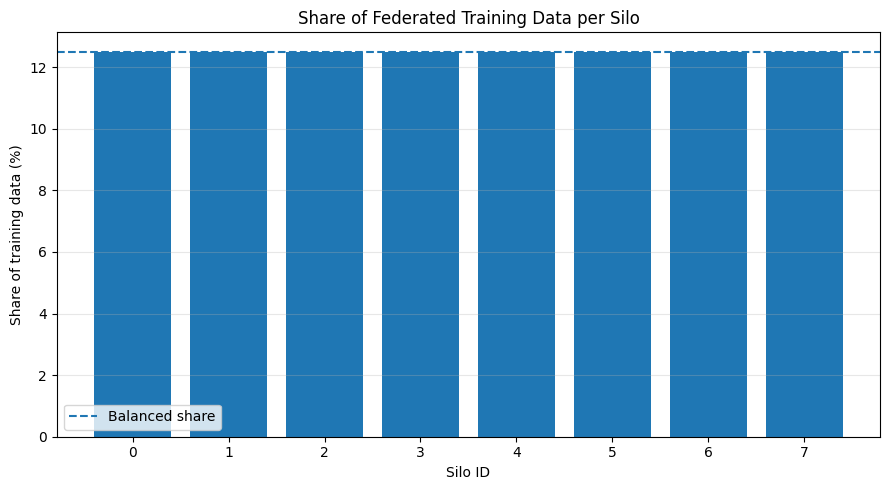

In [16]:
plt.figure(figsize=(9, 5))

plt.bar(
    silo_summary["silo_id"],
    silo_summary["share_percent"]
)

plt.axhline(
    100 / NUM_SILOS,
    linestyle="--",
    label="Balanced share"
)

plt.xlabel("Silo ID")
plt.ylabel("Share of training data (%)")
plt.title("Share of Federated Training Data per Silo")
plt.xticks(range(NUM_SILOS))
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
mean_silo_size = silo_summary["num_images"].mean()
std_silo_size = silo_summary["num_images"].std()
coefficient_of_variation = std_silo_size / mean_silo_size
largest_silo = silo_summary["num_images"].max()
smallest_silo = silo_summary["num_images"].min()
max_min_ratio = largest_silo / smallest_silo

print(f"Mean number of images: {mean_silo_size:.2f}")
print(f"Standard deviation: {std_silo_size:.2f}")
print(f"Coefficient of variation: {coefficient_of_variation:.4f}")
print(f"Largest / smallest ratio: {max_min_ratio:.4f}")

Mean number of images: 25481.12
Standard deviation: 13.01
Coefficient of variation: 0.0005
Largest / smallest ratio: 1.0013


In [ ]:
subject_silo_counts = pd.Series({
    subject: len(silos)
    for subject, silos in subject_silo_map.items()
}, name="num_silos")

silo_presence_distribution = (
    subject_silo_counts
    .value_counts()
    .sort_index()
)

single_silo_subjects = int((subject_silo_counts == 1).sum())
multi_silo_subjects = int((subject_silo_counts > 1).sum())
single_silo_percent = 100 * single_silo_subjects / len(member_subjects)
multi_silo_percent = 100 * multi_silo_subjects / len(member_subjects)


print(silo_presence_distribution)
print()
print(f"Subjects present in one Silo: {single_silo_subjects:,}")
print(f"Subjects present in multiple Silos: {multi_silo_subjects:,}")
print(f"Single-Silo percentage: {single_silo_percent:.2f}%")
print(f"Multi-Silo percentage: {multi_silo_percent:.2f}%")

num_silos
1    534
2    770
3    341
4    153
Name: count, dtype: int64

Subjects present in one Silo: 534
Subjects present in multiple Silos: 1,264
Single-Silo percentage: 29.70%
Multi-Silo percentage: 70.30%


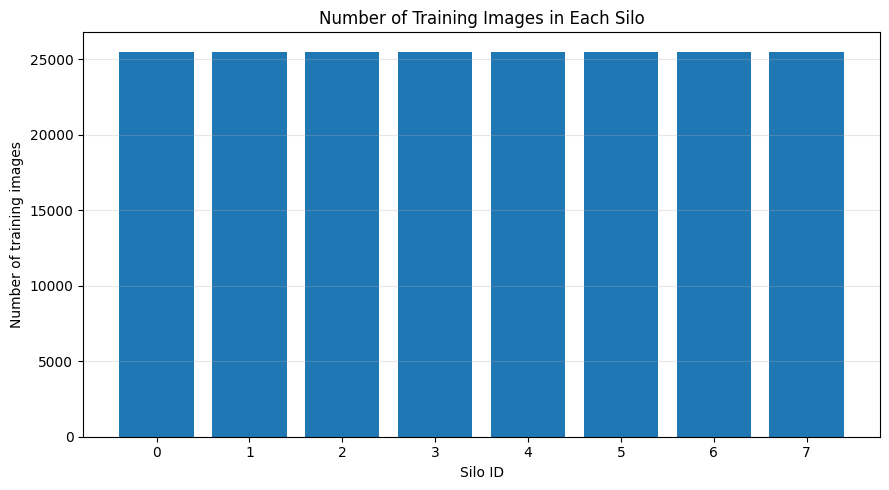

In [19]:
plt.figure(figsize=(9, 5))

plt.bar(
    silo_summary["silo_id"],
    silo_summary["num_images"]
)
plt.xlabel("Silo ID")
plt.ylabel("Number of training images")
plt.title("Number of Training Images in Each Silo")
plt.xticks(range(NUM_SILOS))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

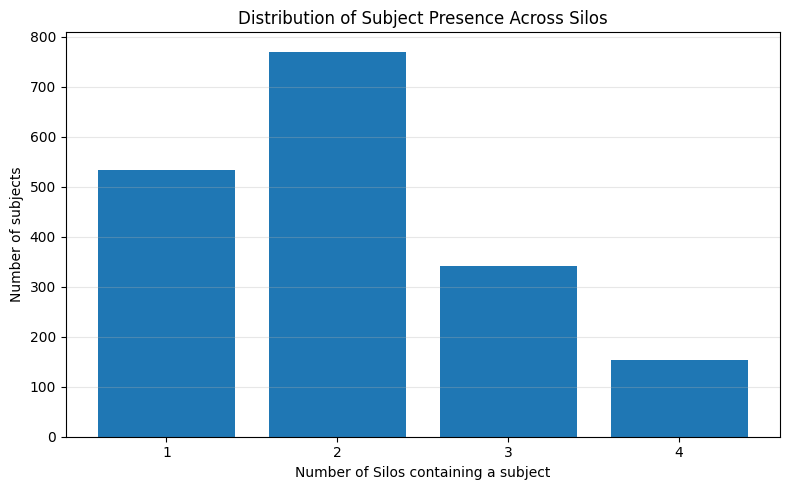

In [20]:
plt.figure(figsize=(8, 5))
plt.bar(
    silo_presence_distribution.index,
    silo_presence_distribution.values
)
plt.xlabel("Number of Silos containing a subject")
plt.ylabel("Number of subjects")
plt.title("Distribution of Subject Presence Across Silos")
plt.xticks(POSSIBLE_SILO_COUNTS)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

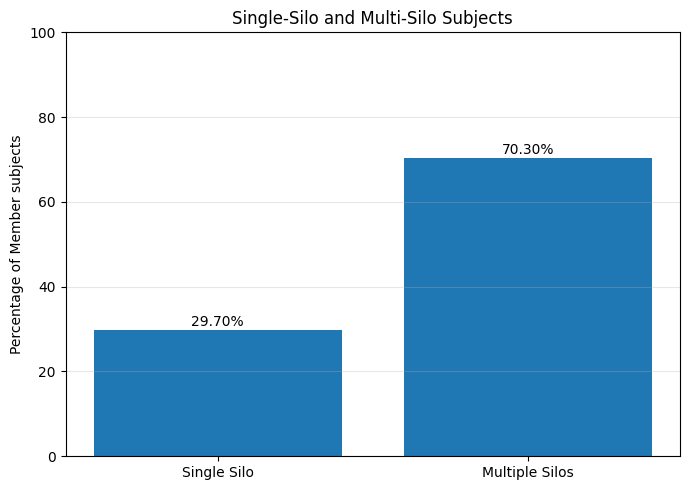

In [21]:
presence_labels = [
    "Single Silo",
    "Multiple Silos"
]

presence_percentages = [
    single_silo_percent,
    multi_silo_percent
]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    presence_labels,
    presence_percentages
)

for bar, value in zip(bars, presence_percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylabel("Percentage of Member subjects")
plt.title("Single-Silo and Multi-Silo Subjects")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
subject_summary_rows = []
for subject in unique_subjects:
    is_member = subject in member_subject_set
    total_samples = len(subject_to_indices[subject])

    if is_member:
        num_train_samples = len(
            member_train_by_subject[subject]
        )

        num_holdout_samples = len(
            member_holdout_by_subject[subject]
        )

        silos = subject_silo_map[subject]
        num_silos = len(silos)
        silo_text = ",".join(map(str, silos))
    else:
        num_train_samples = 0
        num_holdout_samples = total_samples
        num_silos = 0
        silo_text = ""

    subject_summary_rows.append({
        "writer_id": subject,
        "membership": "member" if is_member else "non-member",
        "total_samples": total_samples,
        "training_samples": num_train_samples,
        "holdout_samples": num_holdout_samples,
        "num_silos": num_silos,
        "silos": silo_text
    })

subject_summary = pd.DataFrame(subject_summary_rows)
print(subject_summary.head(10))

  writer_id  membership  total_samples  training_samples  holdout_samples  \
0  f0000_14      member            382               191              191   
1  f0001_41      member            413               206              207   
2  f0002_01  non-member            404                 0              404   
3  f0003_42  non-member            397                 0              397   
4  f0004_09  non-member            315                 0              315   
5  f0005_26  non-member            351                 0              351   
6  f0006_12  non-member            380                 0              380   
7  f0007_14      member            375               187              188   
8  f0008_45      member            418               209              209   
9  f0009_06      member            377               188              189   

   num_silos silos  
0          1     2  
1          2   6,4  
2          0        
3          0        
4          0        
5          0        
6    

### Step2: Training

In [ ]:
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

NUM_ROUNDS = 10
LOCAL_EPOCHS = 1
BATCH_SIZE = 2048
TEST_BATCH_SIZE = 2048
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0
TEST_IMAGES_PER_GROUP = 5000
NUM_WORKERS = 0
PIN_MEMORY = DEVICE.type == "cuda"
FL_OUTPUT_DIR = Path("./femnist_federated")
CHECKPOINT_DIR = FL_OUTPUT_DIR / "checkpoints"
FL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Number of rounds:", NUM_ROUNDS)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)

Device: cuda
Number of rounds: 10
Batch size: 2048
Learning rate: 0.001


In [25]:
test_rng = np.random.default_rng(SEED)

num_member_test = min(
    TEST_IMAGES_PER_GROUP,
    len(member_holdout_indices)
)

num_nonmember_test = min(
    TEST_IMAGES_PER_GROUP,
    len(nonmember_indices)
)

member_test_indices = test_rng.choice(
    member_holdout_indices,
    size=num_member_test,
    replace=False
)

nonmember_test_indices = test_rng.choice(
    nonmember_indices,
    size=num_nonmember_test,
    replace=False
)

global_test_indices = np.concatenate([
    member_test_indices,
    nonmember_test_indices
])

test_rng.shuffle(global_test_indices)

print(f"Member test images: {len(member_test_indices):,}")
print(f"Non-member test images: {len(nonmember_test_indices):,}")
print(f"Total test images: {len(global_test_indices):,}")
print(
    "Classes in test set:",
    len(np.unique(labels[global_test_indices]))
)

Member test images: 5,000
Non-member test images: 5,000
Total test images: 10,000
Classes in test set: 62


In [26]:
member_attack_pool_indices = np.setdiff1d(
    member_holdout_indices,
    member_test_indices
)

nonmember_attack_pool_indices = np.setdiff1d(
    nonmember_indices,
    nonmember_test_indices
)

np.savez_compressed(
    FL_OUTPUT_DIR / "evaluation_indices.npz",
    member_test_indices=member_test_indices,
    nonmember_test_indices=nonmember_test_indices,
    global_test_indices=global_test_indices,
    member_attack_pool_indices=member_attack_pool_indices,
    nonmember_attack_pool_indices=nonmember_attack_pool_indices
)

print(f"Member attack pool: {len(member_attack_pool_indices):,}")
print(f"Non-member attack pool: {len(nonmember_attack_pool_indices):,}")

Member attack pool: 199,740
Non-member attack pool: 400,688


In [27]:
class FEMNISTIndexDataset(Dataset):
    def __init__(self, hf_dataset, indices):
        self.hf_dataset = hf_dataset
        self.indices = np.asarray(
            indices,
            dtype=np.int64
        )

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        dataset_index = int(self.indices[position])
        sample = self.hf_dataset[dataset_index]

        image = np.array(
            sample["image"],
            dtype=np.float32,
            copy=True
        )

        if image.ndim == 3:
            image = image[:, :, 0]

        image = torch.from_numpy(image).unsqueeze(0)
        image = image / 255.0
        image = (image - 0.5) / 0.5
        label = torch.tensor(
            int(sample["character"]),
            dtype=torch.long
        )

        return image, label

In [28]:
def make_loader(
    indices,
    batch_size,
    shuffle,
    seed
):
    dataset = FEMNISTIndexDataset(
        femnist,
        indices
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        generator=generator if shuffle else None
    )

In [29]:
global_test_loader = make_loader(
    global_test_indices,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    seed=SEED
)

member_test_loader = make_loader(
    member_test_indices,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    seed=SEED
)

nonmember_test_loader = make_loader(
    nonmember_test_indices,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    seed=SEED
)

In [30]:
test_images, test_labels = next(
    iter(global_test_loader)
)

print("Image batch shape:", test_images.shape)
print("Label batch shape:", test_labels.shape)
print("Pixel minimum:", test_images.min().item())
print("Pixel maximum:", test_images.max().item())

Image batch shape: torch.Size([2048, 1, 28, 28])
Label batch shape: torch.Size([2048])
Pixel minimum: -1.0
Pixel maximum: 1.0


In [31]:
class FEMNISTCNN(nn.Module):
    def __init__(self, num_classes=62):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=5,
            padding=2
        )

        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=5,
            padding=2
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.fc1 = nn.Linear(
            64 * 7 * 7,
            512
        )

        self.fc2 = nn.Linear(
            512,
            num_classes
        )

    def forward(self, x):
        x = self.pool(
            F.relu(self.conv1(x))
        )

        x = self.pool(
            F.relu(self.conv2(x))
        )

        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [32]:
global_model = FEMNISTCNN(
    num_classes=num_classes
).to(DEVICE)

num_parameters = sum(
    parameter.numel()
    for parameter in global_model.parameters()
)

print(global_model)
print(f"Number of model parameters: {num_parameters:,}")

FEMNISTCNN(
  (conv1): Conv2d(1, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=62, bias=True)
)
Number of model parameters: 1,690,046


In [33]:
def train_local_model(
    model,
    loader,
    local_epochs
):
    model.train()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for _ in range(local_epochs):
        for images, targets in loader:
            images = images.to(
                DEVICE,
                non_blocking=True
            )

            targets = targets.to(
                DEVICE,
                non_blocking=True
            )

            optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, targets)

            loss.backward()
            optimizer.step()

            batch_size = targets.size(0)

            total_loss += (
                loss.item() * batch_size
            )

            total_correct += (
                logits.argmax(dim=1) == targets
            ).sum().item()

            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

In [34]:
@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()

    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=True
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True
        )

        logits = model(images)
        loss = criterion(logits, targets)

        batch_size = targets.size(0)

        total_loss += loss.item() * batch_size

        total_correct += (
            logits.argmax(dim=1) == targets
        ).sum().item()

        total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

def get_cpu_state_dict(model):
    return {
        name: tensor.detach().cpu().clone()
        for name, tensor in model.state_dict().items()
    }

In [ ]:
def fedavg(local_state_dicts, local_sizes):
    total_size = float(sum(local_sizes))

    averaged_state = {}

    for name in local_state_dicts[0].keys():
        reference_tensor = local_state_dicts[0][name]

        if torch.is_floating_point(reference_tensor):
            averaged_tensor = torch.zeros_like(reference_tensor)

            for state_dict, size in zip(local_state_dicts, local_sizes):
                weight = size / total_size
                averaged_tensor += state_dict[name] * weight

            averaged_state[name] = averaged_tensor
        else:
            averaged_state[name] = reference_tensor.clone()

    return averaged_state

In [36]:
training_configuration = {
    "seed": SEED,
    "num_silos": NUM_SILOS,
    "num_rounds": NUM_ROUNDS,
    "local_epochs": LOCAL_EPOCHS,
    "batch_size": BATCH_SIZE,
    "test_batch_size": TEST_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "optimizer": "Adam",
    "aggregation": "FedAvg",
    "all_silos_participate_each_round": True,
    "num_training_images": int(
        len(member_train_indices)
    ),
    "num_test_images": int(
        len(global_test_indices)
    ),
    "model": "Two convolution layers and two linear layers"
}

with open(
    FL_OUTPUT_DIR / "training_configuration.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        training_configuration,
        file,
        indent=2
    )

In [ ]:
torch.save(
    {
        "round": 0,
        "model_state_dict": get_cpu_state_dict(
            global_model
        ),
        "training_configuration": (
            training_configuration
        )
    },
    CHECKPOINT_DIR / "round_000.pt"
)

print("Initial model checkpoint saved.")

Initial model checkpoint saved.


In [ ]:
training_history = []
training_start_time = time.time()

for round_number in range(1, NUM_ROUNDS + 1):
    round_start_time = time.time()

    global_state = get_cpu_state_dict(global_model)

    local_state_dicts = []
    local_sizes = []

    round_loss_sum = 0.0
    round_correct_sum = 0.0
    round_sample_count = 0

    silo_progress = tqdm(
        range(NUM_SILOS),
        desc=f"Round {round_number}/{NUM_ROUNDS}",
        leave=False
    )

    for silo_id in silo_progress:
        local_model = FEMNISTCNN(num_classes=num_classes).to(DEVICE)
        local_model.load_state_dict(global_state)

        local_loader = make_loader(
            silo_indices[silo_id],
            batch_size=BATCH_SIZE,
            shuffle=True,
            seed=SEED + round_number * NUM_SILOS + silo_id
        )

        local_loss, local_accuracy = train_local_model(
            local_model,
            local_loader,
            LOCAL_EPOCHS
        )

        silo_size = len(silo_indices[silo_id])

        local_state_dicts.append(get_cpu_state_dict(local_model))
        local_sizes.append(silo_size)

        round_loss_sum += local_loss * silo_size
        round_correct_sum += local_accuracy * silo_size
        round_sample_count += silo_size

        silo_progress.set_postfix(
            silo=silo_id,
            loss=f"{local_loss:.4f}",
            acc=f"{local_accuracy:.4f}"
        )

        del local_model

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    averaged_state = fedavg(local_state_dicts, local_sizes)
    global_model.load_state_dict(averaged_state)

    federated_train_loss = round_loss_sum / round_sample_count
    federated_train_accuracy = round_correct_sum / round_sample_count

    test_loss, test_accuracy = evaluate_model(
        global_model,
        global_test_loader
    )

    round_time = time.time() - round_start_time

    training_history.append({
        "round": round_number,
        "train_loss": federated_train_loss,
        "train_accuracy": federated_train_accuracy,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "round_time_seconds": round_time
    })

    history_df = pd.DataFrame(training_history)

    history_df.to_csv(
        FL_OUTPUT_DIR / "federated_history.csv",
        index=False
    )

    torch.save(
        {
            "round": round_number,
            "model_state_dict": get_cpu_state_dict(global_model),
            "train_loss": federated_train_loss,
            "train_accuracy": federated_train_accuracy,
            "test_loss": test_loss,
            "test_accuracy": test_accuracy
        },
        CHECKPOINT_DIR / f"round_{round_number:03d}.pt"
    )

    print(
        f"Round {round_number:02d} | "
        f"Train Loss: {federated_train_loss:.4f} | "
        f"Train Acc: {100 * federated_train_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {100 * test_accuracy:.2f}% | "
        f"Time: {round_time:.1f}s"
    )

total_training_time = time.time() - training_start_time

print()
print(f"Total training time: {total_training_time / 60:.2f} minutes")

Round 1/10:   0%|          | 0/8 [00:00<?, ?it/s]

Round 01 | Train Loss: 3.7269 | Train Acc: 9.43% | Test Loss: 3.5700 | Test Acc: 23.04% | Time: 98.9s


Round 2/10:   0%|          | 0/8 [00:00<?, ?it/s]

Round 02 | Train Loss: 3.4206 | Train Acc: 21.18% | Test Loss: 3.0116 | Test Acc: 34.45% | Time: 93.0s


Round 3/10:   0%|          | 0/8 [00:00<?, ?it/s]

...

Round 08 | Train Loss: 1.6173 | Train Acc: 56.45% | Test Loss: 1.4018 | Test Acc: 62.05% | Time: 90.8s


Round 9/10:   0%|          | 0/8 [00:00<?, ?it/s]

Round 09 | Train Loss: 1.4935 | Train Acc: 59.51% | Test Loss: 1.2945 | Test Acc: 64.85% | Time: 89.5s


Round 10/10:   0%|          | 0/8 [00:00<?, ?it/s]

Round 10 | Train Loss: 1.3556 | Train Acc: 62.07% | Test Loss: 1.1662 | Test Acc: 67.47% | Time: 89.8s

Total training time: 15.25 minutes


In [ ]:
final_test_loss, final_test_accuracy = evaluate_model(
    global_model,
    global_test_loader
)

member_test_loss, member_test_accuracy = evaluate_model(
    global_model,
    member_test_loader
)

nonmember_test_loss, nonmember_test_accuracy = evaluate_model(
    global_model,
    nonmember_test_loader
)

print("FINAL GLOBAL MODEL RESULTS")

print(f"Combined test loss: {final_test_loss:.4f}")
print(f"Combined test accuracy: {100 * final_test_accuracy:.2f}%")
print(f"Member holdout accuracy: {100 * member_test_accuracy:.2f}%")
print(f"Non-member accuracy: {100 * nonmember_test_accuracy:.2f}%")

FINAL GLOBAL MODEL RESULTS
Combined test loss: 1.1662
Combined test accuracy: 67.47%
Member holdout accuracy: 67.96%
Non-member accuracy: 66.98%


In [ ]:
final_results = {
    "final_test_loss": float(
        final_test_loss
    ),
    "final_test_accuracy": float(
        final_test_accuracy
    ),
    "member_test_loss": float(
        member_test_loss
    ),
    "member_test_accuracy": float(
        member_test_accuracy
    ),
    "nonmember_test_loss": float(
        nonmember_test_loss
    ),
    "nonmember_test_accuracy": float(
        nonmember_test_accuracy
    ),
    "total_training_time_seconds": float(
        total_training_time
    )
}

with open(
    FL_OUTPUT_DIR / "final_results.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        final_results,
        file,
        indent=2
    )

In [ ]:
torch.save(
    {
        "round": NUM_ROUNDS,
        "model_state_dict": get_cpu_state_dict(
            global_model
        ),
        "num_classes": num_classes,
        "final_results": final_results,
        "training_configuration": (
            training_configuration
        )
    },
    FL_OUTPUT_DIR / "final_global_model.pt"
)

print("Final global model saved.")

Final global model saved.


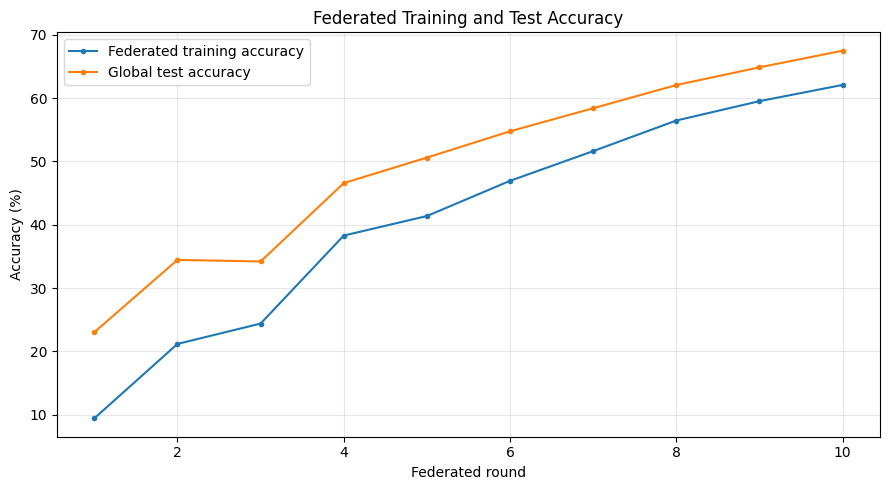

In [ ]:
history_df = pd.DataFrame(
    training_history
)
plt.figure(figsize=(9, 5))
plt.plot(
    history_df["round"],
    100 * history_df["train_accuracy"],
    marker="o",
    markersize=3,
    label="Federated training accuracy"
)

plt.plot(
    history_df["round"],
    100 * history_df["test_accuracy"],
    marker="o",
    markersize=3,
    label="Global test accuracy"
)

plt.xlabel("Federated round")
plt.ylabel("Accuracy (%)")
plt.title("Federated Training and Test Accuracy")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
print(history_df.round(4).to_string(index=False))

 round  train_loss  train_accuracy  test_loss  test_accuracy  round_time_seconds
     1      3.7269          0.0943     3.5700         0.2304             98.8964
     2      3.4206          0.2118     3.0116         0.3445             92.9768
     3      3.2621          0.2440     2.8866         0.3420             91.5806
     4      2.4822          0.3828     2.1104         0.4657             92.0348
     5      2.2780          0.4137     1.9624         0.5060             90.2738
     6      2.0327          0.4693     1.7319         0.5475             89.2385
     7      1.8400          0.5162     1.5824         0.5839             89.7442
     8      1.6173          0.5645     1.4018         0.6205             90.8044
     9      1.4935          0.5951     1.2945         0.6485             89.4560
    10      1.3556          0.6207     1.1662         0.6747             89.7667


In [ ]:
print("Best test round")
best_row = history_df.loc[history_df["test_accuracy"].idxmax()]
print(f"Round: {int(best_row['round'])}")
print(
    f"Test accuracy: "
    f"{100 * best_row['test_accuracy']:.2f}%")
print(
    f"Test loss: "
    f"{best_row['test_loss']:.4f}")

Best test round
Round: 10
Test accuracy: 67.47%
Test loss: 1.1662


In [ ]:
EXTRA_ROUNDS = 10
history_path = FL_OUTPUT_DIR / "federated_history.csv"

if not history_path.exists():
    raise FileNotFoundError("federated_history.csv was not found.")

history_df = pd.read_csv(history_path)

last_completed_round = int(history_df["round"].max())

checkpoint_path = CHECKPOINT_DIR / f"round_{last_completed_round:03d}.pt"

if not checkpoint_path.exists():
    raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

try:
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(checkpoint_path, map_location="cpu")

global_model = FEMNISTCNN(num_classes=num_classes).to(DEVICE)
global_model.load_state_dict(checkpoint["model_state_dict"])

training_history = history_df.to_dict(orient="records")

start_round = last_completed_round + 1
end_round = last_completed_round + EXTRA_ROUNDS

print(f"Continuing training from round {start_round} to round {end_round}")

Continuing training from round 11 to round 20


In [ ]:
continuation_start_time = time.time()

for round_number in range(start_round, end_round + 1):
    round_start_time = time.time()

    global_state = get_cpu_state_dict(global_model)

    local_state_dicts = []
    local_sizes = []

    round_loss_sum = 0.0
    round_correct_sum = 0.0
    round_sample_count = 0

    silo_progress = tqdm(
        range(NUM_SILOS),
        desc=f"Round {round_number}/{end_round}",
        leave=False
    )

    for silo_id in silo_progress:
        local_model = FEMNISTCNN(num_classes=num_classes).to(DEVICE)
        local_model.load_state_dict(global_state)

        local_loader = make_loader(
            silo_indices[silo_id],
            batch_size=BATCH_SIZE,
            shuffle=True,
            seed=SEED + round_number * NUM_SILOS + silo_id
        )

        local_loss, local_accuracy = train_local_model(
            local_model,
            local_loader,
            LOCAL_EPOCHS
        )

        silo_size = len(silo_indices[silo_id])

        local_state_dicts.append(get_cpu_state_dict(local_model))
        local_sizes.append(silo_size)

        round_loss_sum += local_loss * silo_size
        round_correct_sum += local_accuracy * silo_size
        round_sample_count += silo_size

        silo_progress.set_postfix(
            silo=silo_id,
            loss=f"{local_loss:.4f}",
            acc=f"{local_accuracy:.4f}"
        )

        del local_model
        del local_loader

    averaged_state = fedavg(local_state_dicts, local_sizes)
    global_model.load_state_dict(averaged_state)

    federated_train_loss = round_loss_sum / round_sample_count
    federated_train_accuracy = round_correct_sum / round_sample_count

    test_loss, test_accuracy = evaluate_model(
        global_model,
        global_test_loader
    )

    round_time = time.time() - round_start_time

    training_history.append({
        "round": round_number,
        "train_loss": federated_train_loss,
        "train_accuracy": federated_train_accuracy,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "round_time_seconds": round_time
    })

    history_df = pd.DataFrame(training_history)

    history_df.to_csv(
        history_path,
        index=False
    )

    torch.save(
        {
            "round": round_number,
            "model_state_dict": get_cpu_state_dict(global_model),
            "train_loss": federated_train_loss,
            "train_accuracy": federated_train_accuracy,
            "test_loss": test_loss,
            "test_accuracy": test_accuracy
        },
        CHECKPOINT_DIR / f"round_{round_number:03d}.pt"
    )

    print(
        f"Round {round_number:02d} | "
        f"Train Loss: {federated_train_loss:.4f} | "
        f"Train Acc: {100 * federated_train_accuracy:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {100 * test_accuracy:.2f}% | "
        f"Time: {round_time:.1f}s"
    )

continuation_time = time.time() - continuation_start_time

print()
print(f"Continuation time: {continuation_time / 60:.2f} minutes")

Round 11/20:   0%|          | 0/8 [00:00<?, ?it/s]

Round 11 | Train Loss: 1.2275 | Train Acc: 65.39% | Test Loss: 1.0623 | Test Acc: 69.69% | Time: 90.6s


Round 12/20:   0%|          | 0/8 [00:00<?, ?it/s]

Round 12 | Train Loss: 1.1371 | Train Acc: 67.45% | Test Loss: 0.9880 | Test Acc: 71.61% | Time: 93.5s


Round 13/20:   0%|          | 0/8 [00:00<?, ?it/s]

...

Round 18 | Train Loss: 0.7766 | Train Acc: 76.27% | Test Loss: 0.6958 | Test Acc: 79.13% | Time: 94.7s


Round 19/20:   0%|          | 0/8 [00:00<?, ?it/s]

Round 19 | Train Loss: 0.7330 | Train Acc: 77.45% | Test Loss: 0.6633 | Test Acc: 79.62% | Time: 94.2s


Round 20/20:   0%|          | 0/8 [00:00<?, ?it/s]

Round 20 | Train Loss: 0.7167 | Train Acc: 77.90% | Test Loss: 0.6467 | Test Acc: 80.22% | Time: 91.4s

Continuation time: 15.33 minutes


In [ ]:
final_test_loss, final_test_accuracy = evaluate_model(
    global_model,
    global_test_loader
)

member_test_loss, member_test_accuracy = evaluate_model(
    global_model,
    member_test_loader
)

nonmember_test_loss, nonmember_test_accuracy = evaluate_model(
    global_model,
    nonmember_test_loader
)

print("FINAL GLOBAL MODEL RESULTS")
print(f"Combined test loss: {final_test_loss:.4f}")
print(f"Combined test accuracy: {100 * final_test_accuracy:.2f}%")
print(f"Member holdout accuracy: {100 * member_test_accuracy:.2f}%")
print(f"Non-member accuracy: {100 * nonmember_test_accuracy:.2f}%")

FINAL GLOBAL MODEL RESULTS
Combined test loss: 0.6467
Combined test accuracy: 80.22%
Member holdout accuracy: 80.34%
Non-member accuracy: 80.10%


In [ ]:
history_df = pd.DataFrame(training_history)

total_training_time = float(history_df["round_time_seconds"].sum())

final_results = {
    "final_round": int(end_round),
    "final_test_loss": float(final_test_loss),
    "final_test_accuracy": float(final_test_accuracy),
    "member_test_loss": float(member_test_loss),
    "member_test_accuracy": float(member_test_accuracy),
    "nonmember_test_loss": float(nonmember_test_loss),
    "nonmember_test_accuracy": float(nonmember_test_accuracy),
    "total_training_time_seconds": total_training_time
}

with open(
    FL_OUTPUT_DIR / "final_results.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(final_results, file, indent=2)

training_configuration["num_rounds"] = int(end_round)

with open(
    FL_OUTPUT_DIR / "training_configuration.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(training_configuration, file, indent=2)

torch.save(
    {
        "round": end_round,
        "model_state_dict": get_cpu_state_dict(global_model),
        "num_classes": num_classes,
        "final_results": final_results,
        "training_configuration": training_configuration
    },
    FL_OUTPUT_DIR / "final_global_model.pt"
)

print("Updated final model saved.")

Updated final model saved.


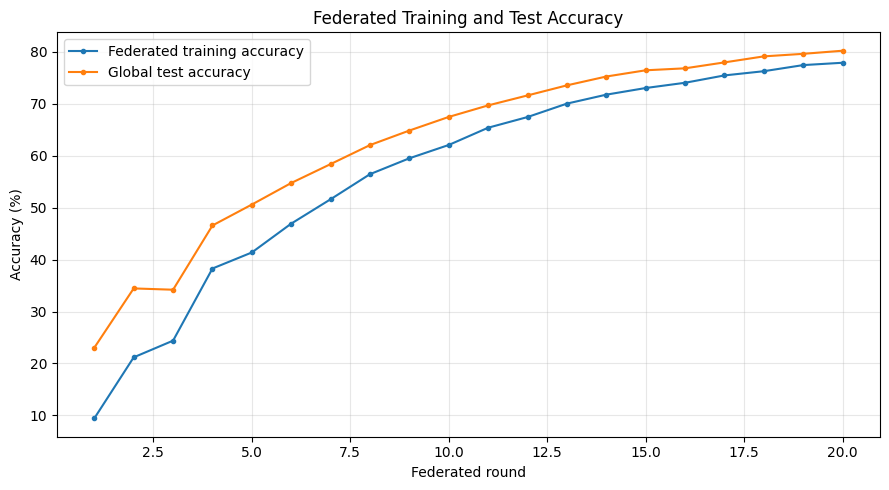

In [ ]:
history_df = pd.read_csv(FL_OUTPUT_DIR / "federated_history.csv")
plt.figure(figsize=(9, 5))
plt.plot(
    history_df["round"],
    100 * history_df["train_accuracy"],
    marker="o",
    markersize=3,
    label="Federated training accuracy"
)

plt.plot(
    history_df["round"],
    100 * history_df["test_accuracy"],
    marker="o",
    markersize=3,
    label="Global test accuracy"
)

plt.xlabel("Federated round")
plt.ylabel("Accuracy (%)")
plt.title("Federated Training and Test Accuracy")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

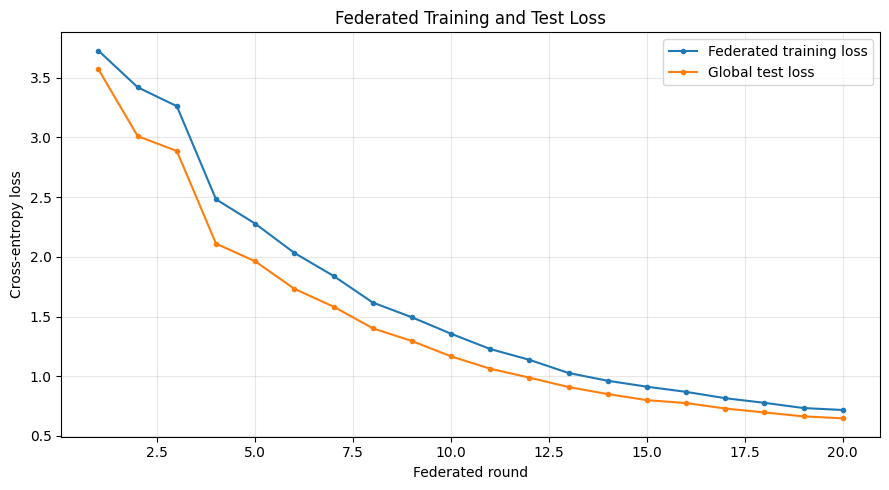

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(
    history_df["round"],
    history_df["train_loss"],
    marker="o",
    markersize=3,
    label="Federated training loss"
)

plt.plot(
    history_df["round"],
    history_df["test_loss"],
    marker="o",
    markersize=3,
    label="Global test loss"
)

plt.xlabel("Federated round")
plt.ylabel("Cross-entropy loss")
plt.title("Federated Training and Test Loss")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Step3: Membership Inference Attack

In [ ]:
ATTACK_SEED = SEED + 2
SUBJECTS_PER_CLASS = 200
SUBJECT_VALIDATION_FRACTION = 0.5
MAX_RECORDS_PER_SUBJECT = 50
MIN_RECORDS_PER_SUBJECT = 20
RECORDS_PER_CLASS = 4000
RECORD_VALIDATION_FRACTION = 0.4
ATTACK_BATCH_SIZE = 2048
ATTACK_NUM_WORKERS = 0
ATTACK_PIN_MEMORY = DEVICE.type == "cuda"
ATTACK_OUTPUT_DIR = Path("./femnist_attacks")
ATTACK_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
attack_rng = np.random.default_rng(ATTACK_SEED)
print("Device:", DEVICE)
print("Subject samples per class:", SUBJECTS_PER_CLASS)
print("Record samples per class:", RECORDS_PER_CLASS)

Device: cuda
Subject samples per class: 200
Record samples per class: 4000


In [ ]:
evaluation_path = (
    FL_OUTPUT_DIR /
    "evaluation_indices.npz"
)

if not evaluation_path.exists():
    raise FileNotFoundError(
        f"Evaluation file was not found: {evaluation_path}"
    )

evaluation_data = np.load(evaluation_path)
member_test_indices = evaluation_data["member_test_indices"]
nonmember_test_indices = evaluation_data["nonmember_test_indices"]
member_attack_pool_indices = evaluation_data["member_attack_pool_indices"]
nonmember_attack_pool_indices = evaluation_data["nonmember_attack_pool_indices"]
print("Member subject-attack pool:",f"{len(member_attack_pool_indices):,}")
print("Non-member subject-attack pool:",f"{len(nonmember_attack_pool_indices):,}")

Member subject-attack pool: 199,740
Non-member subject-attack pool: 400,688


In [ ]:
member_pool_mask = np.zeros(num_samples, dtype=bool)
member_pool_mask[member_attack_pool_indices] = True

nonmember_pool_mask = np.zeros(num_samples, dtype=bool)
nonmember_pool_mask[nonmember_attack_pool_indices] = True


def get_available_subject_indices(subject, availability_mask):
    indices = subject_to_indices[subject]
    return indices[availability_mask[indices]]


eligible_member_subjects = []

for subject in member_subjects:
    available = get_available_subject_indices(subject, member_pool_mask)

    if len(available) >= MIN_RECORDS_PER_SUBJECT:
        eligible_member_subjects.append(subject)

eligible_nonmember_subjects = []

for subject in nonmember_subjects:
    available = get_available_subject_indices(subject, nonmember_pool_mask)

    if len(available) >= MIN_RECORDS_PER_SUBJECT:
        eligible_nonmember_subjects.append(subject)

num_selected_subjects = min(
    SUBJECTS_PER_CLASS,
    len(eligible_member_subjects),
    len(eligible_nonmember_subjects)
)

selected_member_subjects = attack_rng.choice(
    np.asarray(eligible_member_subjects),
    size=num_selected_subjects,
    replace=False
)

selected_nonmember_subjects = attack_rng.choice(
    np.asarray(eligible_nonmember_subjects),
    size=num_selected_subjects,
    replace=False
)

attack_rng.shuffle(selected_member_subjects)
attack_rng.shuffle(selected_nonmember_subjects)

print("Selected Member subjects:", len(selected_member_subjects))
print("Selected Non-member subjects:", len(selected_nonmember_subjects))

Selected Member subjects: 200
Selected Non-member subjects: 200


In [ ]:
num_subject_validation = int(
    round(
        SUBJECT_VALIDATION_FRACTION *
        num_selected_subjects
    )
)

member_validation_subjects = selected_member_subjects[:num_subject_validation]
member_evaluation_subjects = selected_member_subjects[num_subject_validation:]
nonmember_validation_subjects = selected_nonmember_subjects[:num_subject_validation]
nonmember_evaluation_subjects = selected_nonmember_subjects[num_subject_validation:]
print(
    "Validation subjects:",
    len(member_validation_subjects) +
    len(nonmember_validation_subjects)
)

print(
    "Evaluation subjects:",
    len(member_evaluation_subjects) +
    len(nonmember_evaluation_subjects)
)

Validation subjects: 200
Evaluation subjects: 200


In [41]:
subject_rows = []
subject_record_parts = []
subject_group_parts = []

subject_groups = [
    (
        member_validation_subjects,
        1,
        "validation",
        member_pool_mask
    ),
    (
        nonmember_validation_subjects,
        0,
        "validation",
        nonmember_pool_mask
    ),
    (
        member_evaluation_subjects,
        1,
        "evaluation",
        member_pool_mask
    ),
    (
        nonmember_evaluation_subjects,
        0,
        "evaluation",
        nonmember_pool_mask
    )
]

In [ ]:
group_id = 0
for subjects, membership, split, pool_mask in subject_groups:
    for subject in subjects:
        available_indices = (
            get_available_subject_indices(
                subject,
                pool_mask
            )
        )

        num_records = min(
            MAX_RECORDS_PER_SUBJECT,
            len(available_indices)
        )

        chosen_indices = attack_rng.choice(
            available_indices,
            size=num_records,
            replace=False
        )
        subject_record_parts.append(chosen_indices)
        subject_group_parts.append(
            np.full(
                num_records,
                group_id,
                dtype=np.int64
            )
        )
        subject_rows.append({
            "group_id": group_id,
            "writer_id": str(subject),
            "membership": membership,
            "split": split,
            "num_records": num_records
        })

        group_id += 1

In [ ]:
subject_attack_table = pd.DataFrame(subject_rows)
subject_attack_indices = np.concatenate(subject_record_parts)
subject_attack_group_ids = np.concatenate(subject_group_parts)
subject_labels = subject_attack_table["membership"].to_numpy(dtype=np.int64)
subject_validation_mask = (
    subject_attack_table["split"]
    .to_numpy() == "validation"
)

subject_evaluation_mask = subject_attack_table["split"].to_numpy() == "evaluation"
subject_attack_table.to_csv(
    ATTACK_OUTPUT_DIR /
    "subject_attack_subjects.csv",
    index=False
)

print(subject_attack_table.groupby(
    ["split", "membership"]
).size())

print(
    "Total subject-attack records:",
    f"{len(subject_attack_indices):,}"
)

split       membership
evaluation  0             100
            1             100
validation  0             100
            1             100
dtype: int64
Total subject-attack records: 19,953


In [44]:
num_record_samples = min(
    RECORDS_PER_CLASS,
    len(member_train_indices),
    len(member_attack_pool_indices)
)

record_member_indices = attack_rng.choice(
    member_train_indices,
    size=num_record_samples,
    replace=False
)

record_nonmember_indices = attack_rng.choice(
    member_attack_pool_indices,
    size=num_record_samples,
    replace=False
)

attack_rng.shuffle(record_member_indices)
attack_rng.shuffle(record_nonmember_indices)

In [ ]:
num_record_validation = int(round(RECORD_VALIDATION_FRACTION *num_record_samples))
record_member_validation = record_member_indices[:num_record_validation]
record_member_evaluation =record_member_indices[num_record_validation:]
record_nonmember_validation = record_nonmember_indices[:num_record_validation]
record_nonmember_evaluation = record_nonmember_indices[num_record_validation:]

In [ ]:
record_attack_indices = np.concatenate([
    record_member_validation,
    record_nonmember_validation,
    record_member_evaluation,
    record_nonmember_evaluation
])

record_labels = np.concatenate([
    np.ones(len(record_member_validation), dtype=np.int64),
    np.zeros(len(record_nonmember_validation), dtype=np.int64),
    np.ones(len(record_member_evaluation), dtype=np.int64),
    np.zeros(len(record_nonmember_evaluation), dtype=np.int64)
])

record_splits = np.concatenate([
    np.full(len(record_member_validation), "validation"),
    np.full(len(record_nonmember_validation), "validation"),
    np.full(len(record_member_evaluation), "evaluation"),
    np.full(len(record_nonmember_evaluation), "evaluation")
])

record_validation_mask = record_splits == "validation"
record_evaluation_mask = record_splits == "evaluation"

In [ ]:
record_attack_table = pd.DataFrame({
    "dataset_index": record_attack_indices,
    "membership": record_labels,
    "split": record_splits,
    "writer_id": writer_ids[
        record_attack_indices
    ]
})

record_attack_table.to_csv(
    ATTACK_OUTPUT_DIR /
    "record_attack_records.csv",
    index=False
)

print(record_attack_table.groupby(
    ["split", "membership"]).size())

print(
    "Total record-attack samples:",
    f"{len(record_attack_indices):,}"
)

split       membership
evaluation  0             2400
            1             2400
validation  0             1600
            1             1600
dtype: int64
Total record-attack samples: 8,000


In [48]:
all_attack_indices = np.unique(
    np.concatenate([
        subject_attack_indices,
        record_attack_indices
    ])
)

ATTACK_CACHE_FILE = (
    ATTACK_OUTPUT_DIR /
    "attack_tensor_cache.pt"
)

In [49]:
def torch_load_compatible(path):
    try:
        return torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )
    except TypeError:
        return torch.load(
            path,
            map_location="cpu"
        )

In [ ]:
rebuild_attack_cache = True

if ATTACK_CACHE_FILE.exists():
    attack_cache = torch_load_compatible(ATTACK_CACHE_FILE)

    cached_attack_indices = np.asarray(
        attack_cache["indices"],
        dtype=np.int64
    )

    if np.array_equal(cached_attack_indices, all_attack_indices):
        cached_attack_images = attack_cache["images"]
        cached_attack_labels = attack_cache["labels"]
        rebuild_attack_cache = False

In [ ]:
if rebuild_attack_cache:
    print("Creating attack image cache")

    image_parts = []
    label_parts = []

    CACHE_BATCH_SIZE = 4096

    for start in tqdm(range(0, len(all_attack_indices), CACHE_BATCH_SIZE)):
        batch_indices = all_attack_indices[start:start + CACHE_BATCH_SIZE]

        batch = femnist[batch_indices.tolist()]

        batch_images = np.stack([
            np.asarray(image, dtype=np.uint8)
            for image in batch["image"]
        ])

        if batch_images.ndim == 4:
            batch_images = batch_images[:, :, :, 0]

        batch_images = torch.from_numpy(batch_images).unsqueeze(1)

        batch_labels = torch.tensor(
            batch["character"],
            dtype=torch.long
        )

        image_parts.append(batch_images)
        label_parts.append(batch_labels)

    cached_attack_indices = all_attack_indices.copy()

    cached_attack_images = torch.cat(image_parts, dim=0)
    cached_attack_labels = torch.cat(label_parts, dim=0)

    torch.save(
        {
            "indices": cached_attack_indices,
            "images": cached_attack_images,
            "labels": cached_attack_labels
        },
        ATTACK_CACHE_FILE
    )

    del image_parts
    del label_parts

In [52]:
def get_attack_cache_positions(
    original_indices
):
    original_indices = np.asarray(
        original_indices,
        dtype=np.int64
    )

    positions = np.searchsorted(
        cached_attack_indices,
        original_indices
    )

    if not np.array_equal(
        cached_attack_indices[positions],
        original_indices
    ):
        raise ValueError(
            "Some attack records are missing "
            "from the cache."
        )

    return positions

In [ ]:
subject_attack_positions = get_attack_cache_positions(subject_attack_indices)
record_attack_positions = get_attack_cache_positions(record_attack_indices)

In [ ]:
class AttackDataset(Dataset):
    def __init__(
        self,
        images,
        labels,
        positions,
        group_ids=None
    ):
        self.images = images
        self.labels = labels

        self.positions = torch.as_tensor(
            positions,
            dtype=torch.long
        )

        if group_ids is None:
            self.group_ids = None
        else:
            self.group_ids = torch.as_tensor(
                group_ids,
                dtype=torch.long
            )

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, index):
        position = self.positions[index]

        image = self.images[position]
        label = self.labels[position]

        if self.group_ids is None:
            return image, label

        return (
            image,
            label,
            self.group_ids[index]
        )

In [ ]:
subject_attack_dataset = AttackDataset(
    cached_attack_images,
    cached_attack_labels,
    subject_attack_positions,
    subject_attack_group_ids
)

record_attack_dataset = AttackDataset(
    cached_attack_images,
    cached_attack_labels,
    record_attack_positions
)

In [56]:
subject_attack_loader = DataLoader(
    subject_attack_dataset,
    batch_size=ATTACK_BATCH_SIZE,
    shuffle=False,
    num_workers=ATTACK_NUM_WORKERS,
    pin_memory=ATTACK_PIN_MEMORY
)

record_attack_loader = DataLoader(
    record_attack_dataset,
    batch_size=ATTACK_BATCH_SIZE,
    shuffle=False,
    num_workers=ATTACK_NUM_WORKERS,
    pin_memory=ATTACK_PIN_MEMORY
)

In [ ]:
@torch.no_grad()
def calculate_subject_losses(model, loader, num_subject_groups):
    model.eval()

    loss_sums = np.zeros(num_subject_groups, dtype=np.float64)
    sample_counts = np.zeros(num_subject_groups, dtype=np.int64)

    for images, targets, group_ids in loader:
        images = images.to(DEVICE, non_blocking=True).float()
        images = images.div(127.5).sub(1.0)

        targets = targets.to(DEVICE, non_blocking=True)

        logits = model(images)

        losses = F.cross_entropy(
            logits,
            targets,
            reduction="none"
        )

        losses = losses.detach().cpu().numpy()
        group_ids = group_ids.numpy()

        loss_sums += np.bincount(
            group_ids,
            weights=losses,
            minlength=num_subject_groups
        )

        sample_counts += np.bincount(
            group_ids,
            minlength=num_subject_groups
        )

    if np.any(sample_counts == 0):
        empty_groups = np.flatnonzero(sample_counts == 0)

        raise ValueError(
            f"Subject groups without records: {empty_groups.tolist()}"
        )

    return loss_sums / sample_counts

In [ ]:
@torch.no_grad()
def calculate_record_losses(
    model,
    loader
):
    model.eval()

    loss_parts = []

    for images, targets in loader:
        images = images.to(
            DEVICE,
            non_blocking=True
        ).float()

        images = images.div(127.5).sub(1.0)

        targets = targets.to(
            DEVICE,
            non_blocking=True
        )

        logits = model(images)

        losses = F.cross_entropy(
            logits,
            targets,
            reduction="none"
        )
        loss_parts.append(losses.detach().cpu().numpy())

    return np.concatenate(loss_parts)

In [ ]:
history_path = (
    FL_OUTPUT_DIR /
    "federated_history.csv"
)

history_df = pd.read_csv(history_path)
FINAL_ATTACK_ROUND = int(history_df["round"].max())
checkpoint_rounds = list(range(0, FINAL_ATTACK_ROUND + 1))
checkpoint_paths = [
    CHECKPOINT_DIR /
    f"round_{round_number:03d}.pt"
    for round_number in checkpoint_rounds
]

missing_checkpoints = [
    str(path)
    for path in checkpoint_paths
    if not path.exists()
]

if missing_checkpoints:
    raise FileNotFoundError(
        "Missing checkpoints:\n" +
        "\n".join(missing_checkpoints)
    )

In [ ]:
attack_model = FEMNISTCNN(num_classes=num_classes).to(DEVICE)
num_subject_groups = len(subject_attack_table)
subject_loss_matrix = np.zeros(
    (
        len(checkpoint_rounds),
        num_subject_groups
    ),
    dtype=np.float32
)

record_loss_matrix = np.zeros(
    (
        len(checkpoint_rounds),
        len(record_attack_indices)
    ),
    dtype=np.float32
)

In [ ]:
for row_index, (round_number, checkpoint_path) in enumerate(
    tqdm(
        list(zip(checkpoint_rounds, checkpoint_paths)),
        desc="Evaluating checkpoints"
    )
):
    checkpoint = torch_load_compatible(checkpoint_path)

    attack_model.load_state_dict(checkpoint["model_state_dict"])

    subject_loss_matrix[row_index] = calculate_subject_losses(
        attack_model,
        subject_attack_loader,
        num_subject_groups
    )

    record_loss_matrix[row_index] = calculate_record_losses(
        attack_model,
        record_attack_loader
    )

Evaluating checkpoints:   0%|          | 0/21 [00:00<?, ?it/s]

In [ ]:
np.savez_compressed(
    ATTACK_OUTPUT_DIR /
    "attack_loss_values.npz",
    rounds=np.asarray(checkpoint_rounds),
    subject_losses=subject_loss_matrix,
    record_losses=record_loss_matrix
)

In [ ]:
def calculate_binary_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }


def find_best_threshold(y_true, scores):
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    youden_j = tpr - fpr
    best_index = int(np.argmax(youden_j))

    return (
        float(thresholds[best_index]),
        float(youden_j[best_index])
    )

In [ ]:
# loss across rounds attack
loss_decreased = subject_loss_matrix[1:] < subject_loss_matrix[:-1]
subject_cumulative_scores = np.cumsum(loss_decreased,axis=0)

In [ ]:
subject_metric_rows = []

for score_row, round_number in enumerate(checkpoint_rounds[1:]):
    scores = subject_cumulative_scores[score_row].astype(np.float64)

    validation_scores = scores[subject_validation_mask]
    validation_labels = subject_labels[subject_validation_mask]

    threshold, validation_f1 = find_best_threshold(
        validation_labels,
        validation_scores
    )

    evaluation_scores = scores[subject_evaluation_mask]
    evaluation_labels = subject_labels[subject_evaluation_mask]

    predictions = (evaluation_scores >= threshold).astype(np.int64)

    metrics = calculate_binary_metrics(
        evaluation_labels,
        predictions
    )

    member_mean_score = evaluation_scores[evaluation_labels == 1].mean()
    nonmember_mean_score = evaluation_scores[evaluation_labels == 0].mean()

    subject_metric_rows.append({
        "round": round_number,
        "threshold": threshold,
        "accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "member_mean_score": member_mean_score,
        "nonmember_mean_score": nonmember_mean_score
    })

In [ ]:
subject_metrics_df = pd.DataFrame(subject_metric_rows)
subject_metrics_df.to_csv(
    ATTACK_OUTPUT_DIR /
    "subject_attack_metrics_by_round.csv",
    index=False
)
print(subject_metrics_df.round(4).to_string(index=False))

 round  threshold  accuracy  precision  recall     f1  member_mean_score  nonmember_mean_score
     1        inf     0.500     0.0000    0.00 0.0000               0.99                  0.99
     2        inf     0.500     0.0000    0.00 0.0000               1.99                  1.99
     3        3.0     0.490     0.4939    0.81 0.6136               2.81                  2.83
     4        4.0     0.495     0.4969    0.81 0.6160               3.81                  3.82
     5        5.0     0.490     0.4938    0.80 0.6107               4.78                  4.82
     6        6.0     0.495     0.4969    0.80 0.6130               5.78                  5.81
     7        7.0     0.500     0.5000    0.80 0.6154               6.78                  6.80
     8        8.0     0.500     0.5000    0.79 0.6124               7.77                  7.79
     9        9.0     0.505     0.5033    0.77 0.6087               8.75                  8.75
    10       10.0     0.495     0.4967    0.75 0.5

In [ ]:
# record level attack
record_metric_rows = []

for row_index, round_number in enumerate(checkpoint_rounds[1:], start=1):
    losses = record_loss_matrix[row_index]
    scores = -losses

    validation_scores = scores[record_validation_mask]
    validation_labels = record_labels[record_validation_mask]

    threshold, validation_f1 = find_best_threshold(
        validation_labels,
        validation_scores
    )

    evaluation_scores = scores[record_evaluation_mask]
    evaluation_labels = record_labels[record_evaluation_mask]

    predictions = (evaluation_scores >= threshold).astype(np.int64)

    metrics = calculate_binary_metrics(
        evaluation_labels,
        predictions
    )

    member_mean_loss = losses[record_evaluation_mask & (record_labels == 1)].mean()
    nonmember_mean_loss = losses[record_evaluation_mask & (record_labels == 0)].mean()

    record_metric_rows.append({
        "round": round_number,
        "threshold": threshold,
        "accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "member_mean_loss": member_mean_loss,
        "nonmember_mean_loss": nonmember_mean_loss
    })

In [ ]:
record_metrics_df = pd.DataFrame(
    record_metric_rows
)
record_metrics_df.to_csv(
    ATTACK_OUTPUT_DIR /
    "record_attack_metrics_by_round.csv",
    index=False
)
print(record_metrics_df.round(4).to_string(index=False))

 round  threshold  accuracy  precision  recall     f1  member_mean_loss  nonmember_mean_loss
     1    -4.5327    0.4944     0.4966  0.8254 0.6201            3.5991               3.5653
     2    -2.5025    0.4833     0.4778  0.3592 0.4101            3.0508               2.9950
     3    -2.1110    0.4867     0.4750  0.2529 0.3301            2.9415               2.8683
     4    -0.9824    0.4871     0.4757  0.2533 0.3306            2.1652               2.0709
     5    -0.5172    0.4935     0.4792  0.1488 0.2270            2.0176               1.9191
     6    -1.9982    0.4898     0.4923  0.6529 0.5613            1.7905               1.7070
     7    -0.6241    0.4902     0.4850  0.3162 0.3828            1.6312               1.5484
     8    -1.0162    0.4948     0.4951  0.5212 0.5078            1.4511               1.3775
     9    -1.5479    0.4896     0.4925  0.6854 0.5732            1.3329               1.2611
    10    -1.9284    0.4935     0.4959  0.7804 0.6064            1.200

In [ ]:
final_subject_result = subject_metrics_df.iloc[-1]
final_record_result = record_metrics_df.iloc[-1]

print("FINAL SUBJECT-LEVEL ATTACK RESULTS")
print(f"Round: {int(final_subject_result['round'])}")
print(f"Threshold: {final_subject_result['threshold']:.4f}")
print(f"Accuracy: {100 * final_subject_result['accuracy']:.2f}%")
print(f"Precision: {100 * final_subject_result['precision']:.2f}%")
print(f"Recall: {100 * final_subject_result['recall']:.2f}%")
print(f"F1-score: {100 * final_subject_result['f1']:.2f}%")

FINAL SUBJECT-LEVEL ATTACK RESULTS
Round: 20
Threshold: 20.0000
Accuracy: 49.00%
Precision: 48.48%
Recall: 32.00%
F1-score: 38.55%


In [ ]:
print("FINAL RECORD-LEVEL ATTACK RESULTS")
print(f"Round: {int(final_record_result['round'])}")
print(f"Loss-score threshold: {final_record_result['threshold']:.4f}")
print(f"Accuracy: {100 * final_record_result['accuracy']:.2f}%")
print(f"Precision: {100 * final_record_result['precision']:.2f}%")
print(f"Recall: {100 * final_record_result['recall']:.2f}%")
print(f"F1-score: {100 * final_record_result['f1']:.2f}%")

FINAL RECORD-LEVEL ATTACK RESULTS
Round: 20
Loss-score threshold: -0.5007
Accuracy: 49.50%
Precision: 49.62%
Recall: 65.33%
F1-score: 56.40%


In [ ]:
final_subject_scores = subject_cumulative_scores[-1]
final_subject_threshold = final_subject_result["threshold"]
final_subject_predictions = (
    final_subject_scores[subject_evaluation_mask] >= final_subject_threshold
).astype(np.int64)

subject_confusion = confusion_matrix(subject_labels[subject_evaluation_mask], final_subject_predictions)
print("Subject-Level confusion matrix")
print(subject_confusion)

Subject-Level confusion matrix
[[66 34]
 [68 32]]


In [ ]:
final_record_scores = -record_loss_matrix[-1]
final_record_threshold = final_record_result["threshold"]
final_record_predictions = (
    final_record_scores[record_evaluation_mask] >= final_record_threshold
).astype(np.int64)
record_confusion = confusion_matrix(record_labels[record_evaluation_mask],final_record_predictions)
print("Record-Level confusion matrix")
print(record_confusion)

Record-Level confusion matrix
[[ 808 1592]
 [ 832 1568]]


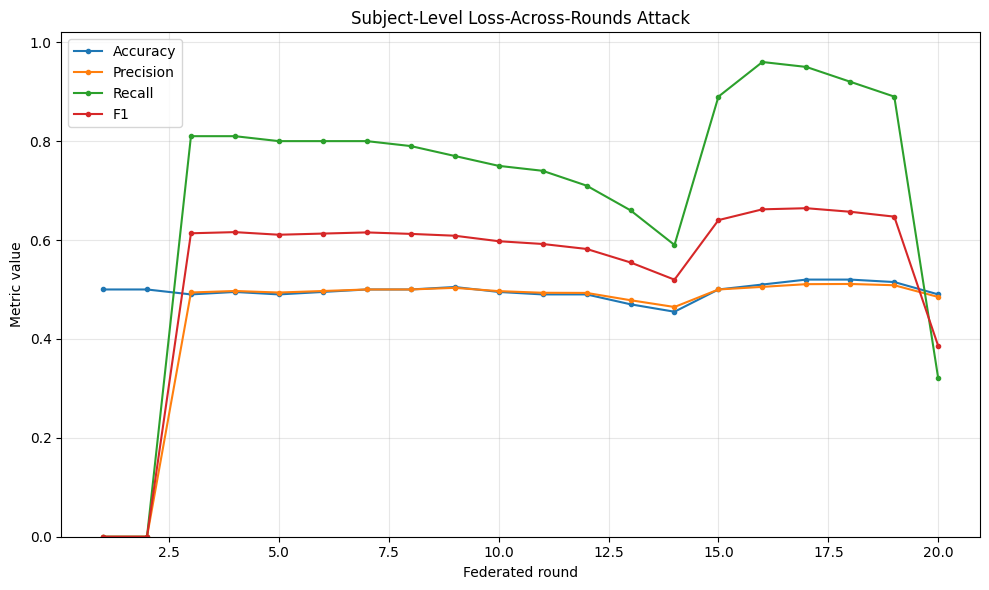

In [ ]:
plt.figure(figsize=(10, 6))

for metric in [
    "accuracy",
    "precision",
    "recall",
    "f1"
]:
    plt.plot(
        subject_metrics_df["round"],
        subject_metrics_df[metric],
        marker="o",
        markersize=3,
        label=metric.capitalize()
    )

plt.xlabel("Federated round")
plt.ylabel("Metric value")
plt.title("Subject-Level Loss-Across-Rounds Attack")
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

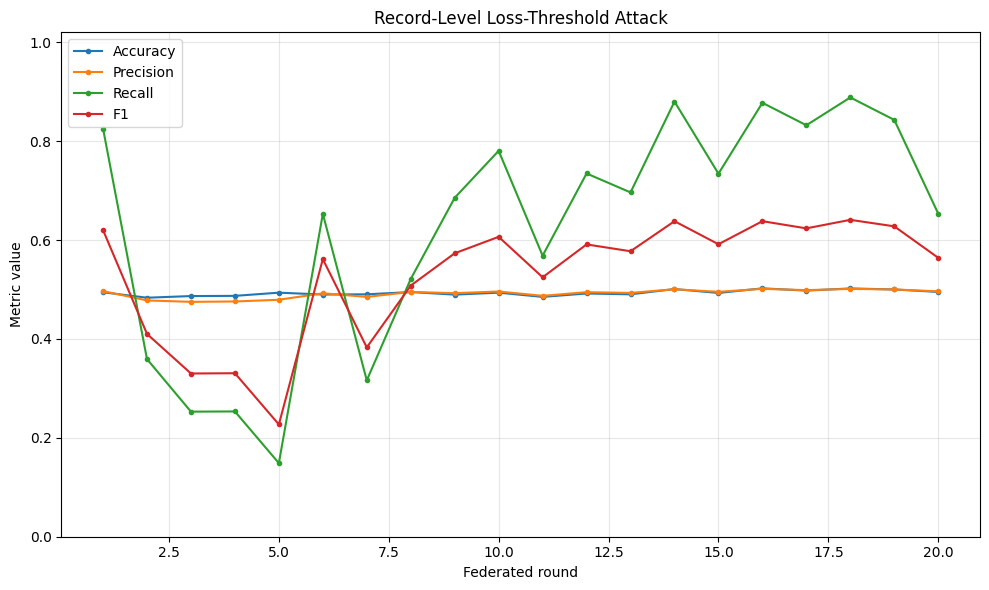

In [ ]:
plt.figure(figsize=(10, 6))

for metric in [
    "accuracy",
    "precision",
    "recall",
    "f1"
]:
    plt.plot(
        record_metrics_df["round"],
        record_metrics_df[metric],
        marker="o",
        markersize=3,
        label=metric.capitalize()
    )

plt.xlabel("Federated round")
plt.ylabel("Metric value")
plt.title("Record-Level Loss-Threshold Attack")
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

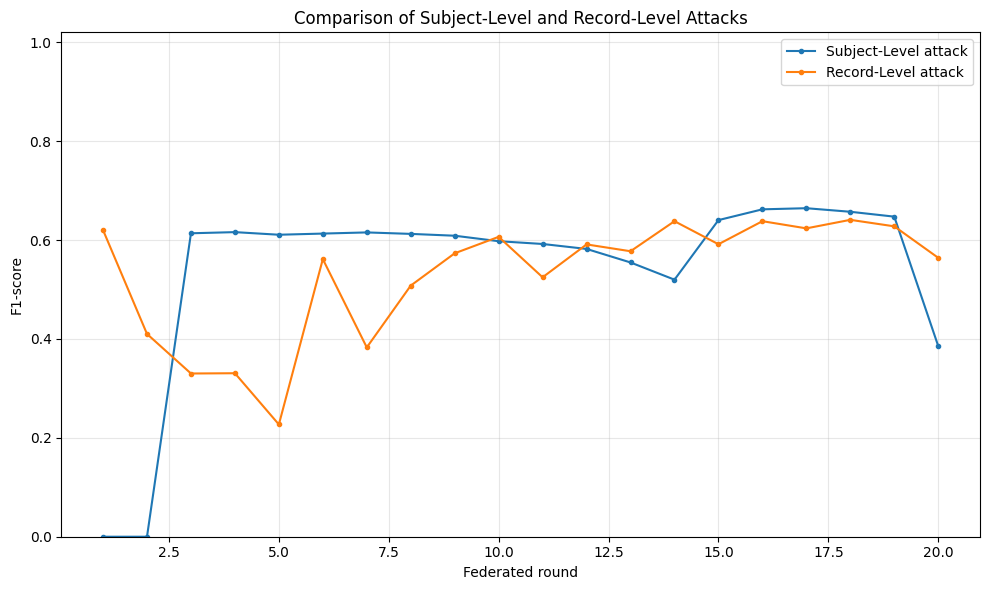

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    subject_metrics_df["round"],
    subject_metrics_df["f1"],
    marker="o",
    markersize=3,
    label="Subject-Level attack"
)

plt.plot(
    record_metrics_df["round"],
    record_metrics_df["f1"],
    marker="o",
    markersize=3,
    label="Record-Level attack"
)

plt.xlabel("Federated round")
plt.ylabel("F1-score")
plt.title(
    "Comparison of Subject-Level "
    "and Record-Level Attacks"
)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
subject_evaluation_labels = subject_labels[subject_evaluation_mask]
evaluation_subject_losses = subject_loss_matrix[:,subject_evaluation_mask]
member_subject_mean_losses = evaluation_subject_losses[:,subject_evaluation_labels == 1].mean(axis=1)
nonmember_subject_mean_losses = evaluation_subject_losses[:,subject_evaluation_labels == 0].mean(axis=1)

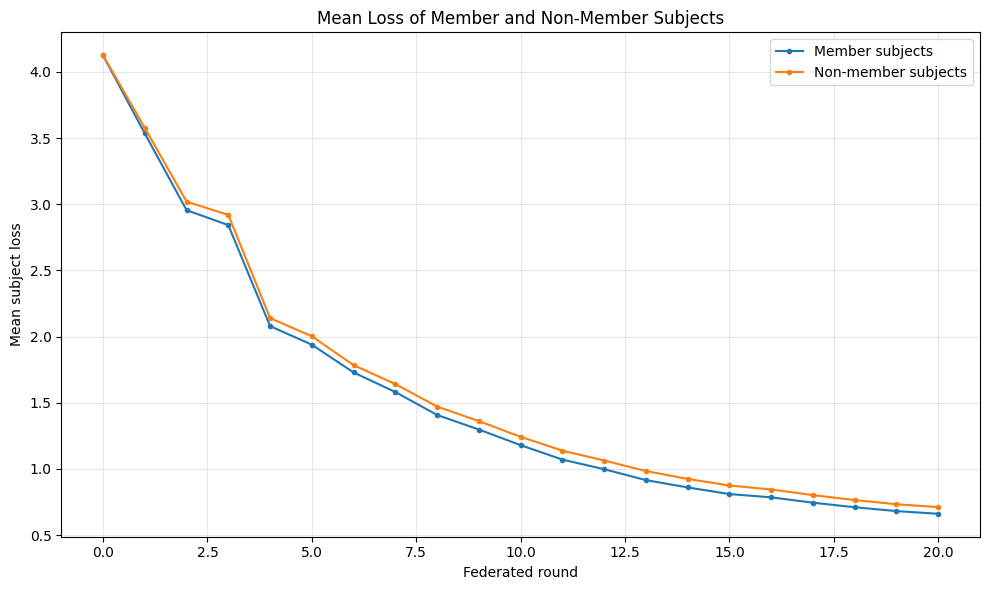

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    checkpoint_rounds,
    member_subject_mean_losses,
    marker="o",
    markersize=3,
    label="Member subjects"
)

plt.plot(
    checkpoint_rounds,
    nonmember_subject_mean_losses,
    marker="o",
    markersize=3,
    label="Non-member subjects"
)

plt.xlabel("Federated round")
plt.ylabel("Mean subject loss")
plt.title(
    "Mean Loss of Member and "
    "Non-Member Subjects"
)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
evaluation_record_losses = record_loss_matrix[:,record_evaluation_mask]
evaluation_record_labels = record_labels[record_evaluation_mask]
member_record_mean_losses = evaluation_record_losses[:,evaluation_record_labels == 1].mean(axis=1)
nonmember_record_mean_losses = evaluation_record_losses[:,evaluation_record_labels == 0].mean(axis=1)

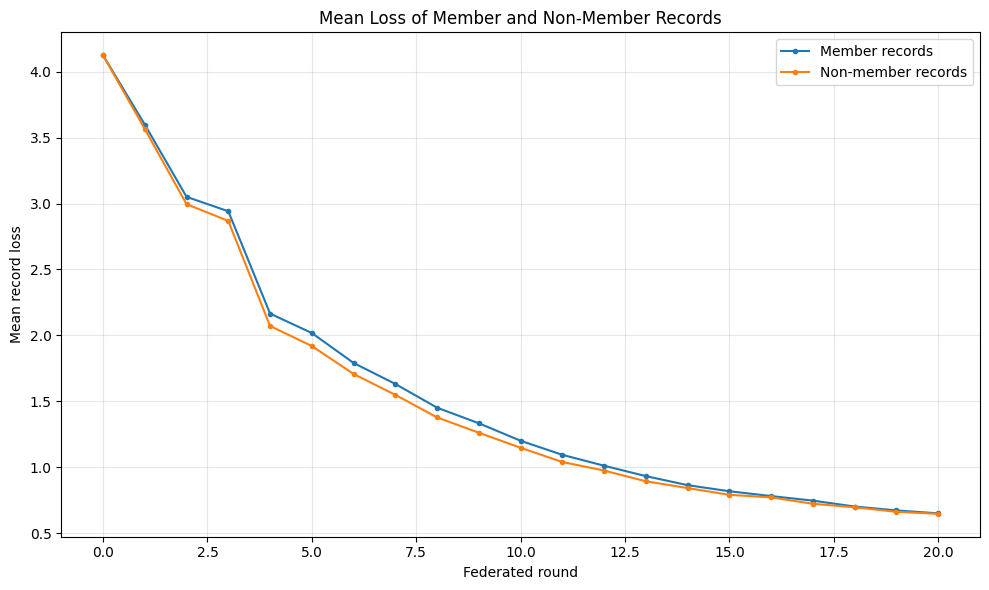

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(
    checkpoint_rounds,
    member_record_mean_losses,
    marker="o",
    markersize=3,
    label="Member records"
)

plt.plot(
    checkpoint_rounds,
    nonmember_record_mean_losses,
    marker="o",
    markersize=3,
    label="Non-member records"
)

plt.xlabel("Federated round")
plt.ylabel("Mean record loss")
plt.title(
    "Mean Loss of Member and "
    "Non-Member Records"
)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Step4: Defence based on Differencial Privacy

In [ ]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif (
    hasattr(torch.backends, "mps")
    and torch.backends.mps.is_available()
):
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

torch.manual_seed(SEED)
np.random.seed(SEED)
TARGET_EPSILON = 4.0
TARGET_DELTA = 1e-5
BASE_DP_ROUNDS = 20
DP_LEARNING_RATE = 0.001
RECORD_CLIP_NORM = 1.0
RECORD_LOGICAL_BATCH_SIZE = 2048
RECORD_PHYSICAL_BATCH_SIZE = 512
SUBJECT_CLIP_NORM = 1.0
SUBJECTS_PER_STEP = 8
RECORDS_PER_SUBJECT_STEP = 8
SUBJECT_STEPS_PER_ROUND = 12
DP_ROOT = Path("./femnist_dp_results")
DP_CACHE_DIR = DP_ROOT / "cache"
DP_ROOT.mkdir(parents=True, exist_ok=True)
DP_CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE)
print("Target epsilon:", TARGET_EPSILON)
print("Target delta:", TARGET_DELTA)

Device: cuda
Target epsilon: 4.0
Target delta: 1e-05


In [ ]:
checkpoint_candidates = []

if "CHECKPOINT_DIR" in globals():
    checkpoint_candidates.append(Path(CHECKPOINT_DIR) / "round_000.pt")

checkpoint_candidates.extend([
    Path("./femnist_federated/checkpoints/round_000.pt"),
    Path("./femnist_federated_fast/checkpoints/round_000.pt")
])

INITIAL_CHECKPOINT_PATH = next(
    (path for path in checkpoint_candidates if path.exists()),
    None
)

if INITIAL_CHECKPOINT_PATH is None:
    raise FileNotFoundError(
        "The initial checkpoint round_000.pt was not found."
    )


def torch_load_compatible(path):
    try:
        return torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )
    except TypeError:
        return torch.load(path, map_location="cpu")


initial_checkpoint = torch_load_compatible(INITIAL_CHECKPOINT_PATH)

INITIAL_MODEL_STATE = {
    name: tensor.detach().cpu().clone()
    for name, tensor in initial_checkpoint["model_state_dict"].items()
}

print("Initial checkpoint:", INITIAL_CHECKPOINT_PATH)

Initial checkpoint: femnist_federated/checkpoints/round_000.pt


In [ ]:
DP_TENSOR_CACHE = DP_CACHE_DIR / "dp_training_tensor_cache.pt"

needed_dp_indices = np.unique(np.concatenate([
    member_train_indices,
    global_test_indices
]))

rebuild_cache = True

if DP_TENSOR_CACHE.exists():
    saved_cache = torch_load_compatible(DP_TENSOR_CACHE)

    saved_indices = np.asarray(
        saved_cache["indices"],
        dtype=np.int64
    )

    if np.array_equal(saved_indices, needed_dp_indices):
        dp_cached_indices = saved_indices
        dp_cached_images = saved_cache["images"]
        dp_cached_labels = saved_cache["labels"]

        rebuild_cache = False
        print("Existing DP cache loaded.")

if rebuild_cache:
    print("Creating DP tensor cache")

    image_parts = []
    label_parts = []

    CACHE_BATCH_SIZE = 4096

    for start in tqdm(range(0, len(needed_dp_indices), CACHE_BATCH_SIZE)):
        batch_indices = needed_dp_indices[start:start + CACHE_BATCH_SIZE]

        batch = femnist[batch_indices.tolist()]

        batch_images = np.stack([
            np.asarray(image, dtype=np.uint8)
            for image in batch["image"]
        ])

        if batch_images.ndim == 4:
            batch_images = batch_images[:, :, :, 0]

        batch_images = torch.from_numpy(batch_images).unsqueeze(1)

        batch_labels = torch.tensor(
            batch["character"],
            dtype=torch.long
        )

        image_parts.append(batch_images)
        label_parts.append(batch_labels)

    dp_cached_indices = needed_dp_indices.copy()

    dp_cached_images = torch.cat(image_parts, dim=0)
    dp_cached_labels = torch.cat(label_parts, dim=0)

    torch.save(
        {
            "indices": dp_cached_indices,
            "images": dp_cached_images,
            "labels": dp_cached_labels
        },
        DP_TENSOR_CACHE
    )

    del image_parts
    del label_parts

    print("DP cache saved.")

Creating DP tensor cache


  0%|          | 0/53 [00:00<?, ?it/s]

DP cache saved.


In [ ]:
def get_dp_cache_positions(original_indices):
    original_indices = np.asarray(original_indices, dtype=np.int64)
    positions = np.searchsorted(dp_cached_indices, original_indices)
    if not np.array_equal(dp_cached_indices[positions],original_indices):
        raise ValueError(
            "Some indices are missing from the DP cache."
        )
    return positions

silo_dp_positions = [
    get_dp_cache_positions(indices)
    for indices in silo_indices
]
global_test_positions = get_dp_cache_positions(global_test_indices)

In [ ]:
class PositionDataset(Dataset):
    def __init__(self, images, labels, positions):
        self.images = images
        self.labels = labels

        self.positions = torch.as_tensor(
            positions,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.positions)

    def __getitem__(self, index):
        position = self.positions[index]

        return (
            self.images[position],
            self.labels[position]
        )

In [ ]:
def make_position_loader(
    positions,
    batch_size,
    shuffle,
    seed
):
    dataset = PositionDataset(
        dp_cached_images,
        dp_cached_labels,
        positions
    )
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda",
        generator=generator if shuffle else None
    )

In [69]:
dp_test_loader = make_position_loader(
    global_test_positions,
    batch_size=2048,
    shuffle=False,
    seed=SEED
)

In [ ]:
def normalize_images(images):
    return images.float().div(127.5).sub(1.0)


def unwrap_model(model):
    current_model = model

    while hasattr(current_model, "_module"):
        current_model = current_model._module

    return current_model


def get_plain_state_dict(model):
    plain_model = unwrap_model(model)

    return {
        name: tensor.detach().cpu().clone()
        for name, tensor in plain_model.state_dict().items()
    }


def clear_optimizer_state(optimizer):
    optimizer.zero_grad(set_to_none=True)

    if hasattr(optimizer, "original_optimizer"):
        optimizer.original_optimizer.state.clear()
    else:
        optimizer.state.clear()


def average_model_states(local_states, local_sizes):
    total_size = float(sum(local_sizes))
    averaged_state = {}

    for name in local_states[0].keys():
        reference = local_states[0][name]

        if torch.is_floating_point(reference):
            value = torch.zeros_like(reference)

            for state, size in zip(local_states, local_sizes):
                value += (size / total_size) * state[name]

            averaged_state[name] = value
        else:
            averaged_state[name] = reference.clone()

    return averaged_state

In [ ]:
@torch.no_grad()
def evaluate_plain_model(model, loader):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, targets in loader:
        images = normalize_images(
            images.to(DEVICE, non_blocking=True)
        )

        targets = targets.to(DEVICE, non_blocking=True)

        logits = model(images)

        loss = F.cross_entropy(logits, targets)

        batch_size = len(targets)

        total_loss += loss.item() * batch_size

        total_correct += (
            logits.argmax(dim=1) == targets
        ).sum().item()

        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [ ]:
def calibrate_record_noise_multipliers(
    rounds=BASE_DP_ROUNDS
):
    noise_multipliers = []

    for silo_id in range(NUM_SILOS):
        num_records = len(silo_dp_positions[silo_id])
        steps_per_round = math.ceil(num_records /RECORD_LOGICAL_BATCH_SIZE)

        sample_rate = 1.0 / steps_per_round
        total_steps = rounds * steps_per_round

        sigma = get_noise_multiplier(
            target_epsilon=TARGET_EPSILON,
            target_delta=TARGET_DELTA,
            sample_rate=sample_rate,
            steps=total_steps,
            accountant="rdp"
        )
        noise_multipliers.append(float(sigma))

    return noise_multipliers

In [ ]:
BASE_RECORD_SIGMAS = calibrate_record_noise_multipliers()
print("Record-Level noise multipliers:")
for silo_id, sigma in enumerate(BASE_RECORD_SIGMAS):
    print(f"Silo {silo_id}: sigma = {sigma:.4f}")
print(
    "Mean sigma:",
    f"{np.mean(BASE_RECORD_SIGMAS):.4f}"
)

Record-Level noise multipliers:
Silo 0: sigma = 1.6895
Silo 1: sigma = 1.6895
Silo 2: sigma = 1.6895
Silo 3: sigma = 1.6895
Silo 4: sigma = 1.6895
Silo 5: sigma = 1.6895
Silo 6: sigma = 1.6895
Silo 7: sigma = 1.6895
Mean sigma: 1.6895


In [ ]:
def create_private_record_client(
    silo_id,
    sigma,
    clipping_norm
):
    dataset = PositionDataset(
        dp_cached_images,
        dp_cached_labels,
        silo_dp_positions[silo_id]
    )

    base_loader = DataLoader(
        dataset,
        batch_size=RECORD_LOGICAL_BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda"
    )

    model = FEMNISTCNN( num_classes=num_classes)
    model.load_state_dict(INITIAL_MODEL_STATE)
    if not ModuleValidator.is_valid(model):
        model = ModuleValidator.fix(model)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=DP_LEARNING_RATE
    )

    criterion = nn.CrossEntropyLoss()
    privacy_engine = PrivacyEngine(accountant="rdp")

    (
        private_model,
        private_optimizer,
        private_criterion,
        private_loader
    ) = privacy_engine.make_private(
        module=model,
        optimizer=optimizer,
        criterion=criterion,
        data_loader=base_loader,
        noise_multiplier=sigma,
        max_grad_norm=clipping_norm,
        poisson_sampling=True,
        grad_sample_mode="ghost"
    )

    private_model.to("cpu")

    return {
        "silo_id": silo_id,
        "model": private_model,
        "optimizer": private_optimizer,
        "criterion": private_criterion,
        "loader": private_loader,
        "privacy_engine": privacy_engine,
        "sigma": sigma,
        "clip": clipping_norm
    }

In [ ]:
def train_private_record_client(client, global_state):
    private_model = client["model"]
    private_optimizer = client["optimizer"]
    private_criterion = client["criterion"]
    private_loader = client["loader"]

    unwrap_model(private_model).load_state_dict(global_state)

    clear_optimizer_state(private_optimizer)

    private_model.to(DEVICE)
    private_model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with BatchMemoryManager(
        data_loader=private_loader,
        max_physical_batch_size=RECORD_PHYSICAL_BATCH_SIZE,
        optimizer=private_optimizer
    ) as safe_loader:
        for images, targets in safe_loader:
            images = normalize_images(
                images.to(DEVICE, non_blocking=True)
            )

            targets = targets.to(DEVICE, non_blocking=True)

            private_optimizer.zero_grad(set_to_none=True)

            logits = private_model(images)

            loss = private_criterion(logits, targets)

            loss.backward()
            private_optimizer.step()

            batch_size = len(targets)

            total_loss += float(loss.item()) * batch_size

            total_correct += (
                logits.argmax(dim=1) == targets
            ).sum().item()

            total_samples += batch_size

    local_state = get_plain_state_dict(private_model)

    clear_optimizer_state(private_optimizer)

    private_model.to("cpu")

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return (
        local_state,
        total_loss / max(total_samples, 1),
        total_correct / max(total_samples, 1)
    )

In [ ]:
def train_record_dp_experiment(
    experiment_name,
    rounds,
    clipping_norm,
    sigma_scale=1.0,
    force=False
):
    experiment_dir = DP_ROOT / experiment_name
    checkpoint_dir = experiment_dir / "checkpoints"
    summary_path = experiment_dir / "training_summary.json"

    if summary_path.exists() and not force:
        print(experiment_name, "already completed.")

        with open(summary_path, "r", encoding="utf-8") as file:
            return json.load(file)

    experiment_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    sigmas = [
        sigma * sigma_scale
        for sigma in BASE_RECORD_SIGMAS
    ]

    clients = [
        create_private_record_client(
            silo_id=silo_id,
            sigma=sigmas[silo_id],
            clipping_norm=clipping_norm
        )
        for silo_id in range(NUM_SILOS)
    ]

    global_model = FEMNISTCNN(num_classes=num_classes).to(DEVICE)
    global_model.load_state_dict(INITIAL_MODEL_STATE)

    torch.save(
        {
            "round": 0,
            "model_state_dict": get_plain_state_dict(global_model)
        },
        checkpoint_dir / "round_000.pt"
    )

    history = []
    start_time = time.time()

    for round_number in range(1, rounds + 1):
        round_start = time.time()
        global_state = get_plain_state_dict(global_model)
        local_states = []
        local_sizes = []
        weighted_loss = 0.0
        weighted_accuracy = 0.0
        total_size = 0

        for client in tqdm(
            clients,
            desc=(
                f"{experiment_name} "
                f"Round {round_number}/{rounds}"
            ),
            leave=False
        ):
            silo_id = client["silo_id"]

            (
                local_state,
                local_loss,
                local_accuracy
            ) = train_private_record_client(
                client,
                global_state
            )

            silo_size = len(silo_dp_positions[silo_id])
            local_states.append(local_state)
            local_sizes.append(silo_size)
            weighted_loss += local_loss * silo_size
            weighted_accuracy += local_accuracy * silo_size
            total_size += silo_size

        averaged_state = average_model_states(
            local_states,
            local_sizes
        )

        global_model.load_state_dict(averaged_state)

        test_loss, test_accuracy = evaluate_plain_model(
            global_model,
            dp_test_loader
        )

        train_loss = weighted_loss / total_size
        train_accuracy = weighted_accuracy / total_size
        round_time = time.time() - round_start

        history.append({
            "round": round_number,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "test_loss": test_loss,
            "test_accuracy": test_accuracy,
            "round_time_seconds": round_time
        })

        pd.DataFrame(history).to_csv(
            experiment_dir / "training_history.csv",
            index=False
        )

        torch.save(
            {
                "round": round_number,
                "model_state_dict": get_plain_state_dict(global_model),
                "test_loss": test_loss,
                "test_accuracy": test_accuracy
            },
            checkpoint_dir / f"round_{round_number:03d}.pt"
        )

        print(
            f"{experiment_name} | "
            f"Round {round_number:02d} | "
            f"Train Acc: "
            f"{100 * train_accuracy:.2f}% | "
            f"Test Acc: "
            f"{100 * test_accuracy:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Time: {round_time:.1f}s"
        )

    epsilons = [
        client["privacy_engine"].get_epsilon(delta=TARGET_DELTA)
        for client in clients
    ]

    total_time = time.time() - start_time

    final_test_loss, final_test_accuracy = evaluate_plain_model(
        global_model,
        dp_test_loader
    )

    summary = {
        "experiment": experiment_name,
        "defense": "record_level_dp_sgd",
        "rounds": rounds,
        "target_delta": TARGET_DELTA,
        "clipping_norm": clipping_norm,
        "sigma_scale": sigma_scale,
        "sigma_mean": float(np.mean(sigmas)),
        "sigma_min": float(np.min(sigmas)),
        "sigma_max": float(np.max(sigmas)),
        "noise_std_mean": float(np.mean(sigmas) * clipping_norm),
        "epsilon_mean": float(np.mean(epsilons)),
        "epsilon_max": float(np.max(epsilons)),
        "final_test_loss": float(final_test_loss),
        "final_test_accuracy": float(final_test_accuracy),
        "training_time_seconds": float(total_time)
    }

    with open(summary_path, "w", encoding="utf-8") as file:
        json.dump(summary, file, indent=2)

    del clients
    del global_model

    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    print(json.dumps(summary, indent=2))

    return summary

In [ ]:
silo_subject_positions = []

for silo_id in range(NUM_SILOS):
    subject_dictionary = {}

    original_indices = np.asarray(
        silo_indices[silo_id],
        dtype=np.int64
    )

    cache_positions = silo_dp_positions[silo_id]

    for original_index, cache_position in zip(
        original_indices, cache_positions
    ):
        subject = writer_ids[original_index]

        if subject not in subject_dictionary:
            subject_dictionary[subject] = []

        subject_dictionary[subject].append(int(cache_position))

    subject_dictionary = {
        subject: np.asarray(positions, dtype=np.int64)
        for subject, positions in subject_dictionary.items()
    }

    silo_subject_positions.append(subject_dictionary)

MAX_SILOS_PER_SUBJECT = max(
    len(silos) for silos in subject_silo_map.values()
)

LOCAL_SUBJECT_EPSILON = TARGET_EPSILON / MAX_SILOS_PER_SUBJECT
LOCAL_SUBJECT_DELTA = TARGET_DELTA / MAX_SILOS_PER_SUBJECT

print("Maximum Silos per Subject:", MAX_SILOS_PER_SUBJECT)
print("Local Subject epsilon:", LOCAL_SUBJECT_EPSILON)
print("Local Subject delta:", LOCAL_SUBJECT_DELTA)

Maximum Silos per Subject: 4
Local Subject epsilon: 1.0
Local Subject delta: 2.5e-06


In [ ]:
def calibrate_subject_sigmas(rounds=BASE_DP_ROUNDS):
    sigmas = []
    sample_rates = []

    total_steps = rounds * SUBJECT_STEPS_PER_ROUND

    for silo_id in range(NUM_SILOS):
        num_subjects = len(silo_subject_positions[silo_id])

        sample_rate = min(
            SUBJECTS_PER_STEP / num_subjects,
            1.0
        )

        sigma = get_noise_multiplier(
            target_epsilon=LOCAL_SUBJECT_EPSILON,
            target_delta=LOCAL_SUBJECT_DELTA,
            sample_rate=sample_rate,
            steps=total_steps,
            accountant="rdp"
        )

        sigmas.append(float(sigma))
        sample_rates.append(float(sample_rate))

    return sigmas, sample_rates

In [ ]:
SUBJECT_SIGMAS, SUBJECT_SAMPLE_RATES = calibrate_subject_sigmas()
for silo_id, sigma in enumerate(SUBJECT_SIGMAS):
    print(
        f"Silo {silo_id}: "
        f"sigma = {sigma:.4f}, "
        f"q = "
        f"{SUBJECT_SAMPLE_RATES[silo_id]:.4f}"
    )

Silo 0: sigma = 1.4746, q = 0.0167
Silo 1: sigma = 1.4941, q = 0.0171
Silo 2: sigma = 1.5039, q = 0.0173
Silo 3: sigma = 1.5332, q = 0.0179
Silo 4: sigma = 1.5332, q = 0.0178
Silo 5: sigma = 1.4941, q = 0.0171
Silo 6: sigma = 1.4746, q = 0.0168
Silo 7: sigma = 1.5039, q = 0.0174


In [ ]:
def subject_private_step(
    model,
    optimizer,
    subject_dictionary,
    sigma,
    clipping_norm,
    rng
):
    all_subjects = np.asarray(list(subject_dictionary.keys()))

    batch_subject_count = min(
        SUBJECTS_PER_STEP,
        len(all_subjects)
    )

    selected_subjects = rng.choice(
        all_subjects,
        size=batch_subject_count,
        replace=False
    )

    parameters = [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ]

    summed_subject_gradients = [
        torch.zeros_like(parameter)
        for parameter in parameters
    ]

    total_loss = 0.0
    total_correct = 0
    total_records = 0

    for subject in selected_subjects:
        available_positions = subject_dictionary[subject]

        num_records = min(
            RECORDS_PER_SUBJECT_STEP,
            len(available_positions)
        )

        chosen_positions = rng.choice(
            available_positions,
            size=num_records,
            replace=False
        )

        images = dp_cached_images[
            torch.as_tensor(chosen_positions, dtype=torch.long)
        ]

        targets = dp_cached_labels[
            torch.as_tensor(chosen_positions, dtype=torch.long)
        ]

        images = normalize_images(
            images.to(DEVICE, non_blocking=True)
        )

        targets = targets.to(DEVICE, non_blocking=True)
        logits = model(images)

        subject_loss = F.cross_entropy(
            logits,
            targets,
            reduction="mean"
        )

        subject_gradients = torch.autograd.grad(
            subject_loss,
            parameters,
            retain_graph=False,
            create_graph=False
        )

        squared_norm = torch.zeros((), device=DEVICE)

        for gradient in subject_gradients:
            squared_norm += gradient.detach().pow(2).sum()

        gradient_norm = torch.sqrt(squared_norm)

        clipping_factor = min(
            1.0,
            clipping_norm / (gradient_norm.item() + 1e-12)
        )

        for accumulator, gradient in zip(
            summed_subject_gradients, subject_gradients
        ):
            accumulator.add_(
                gradient.detach(),
                alpha=clipping_factor
            )

        total_loss += subject_loss.item() * num_records

        total_correct += (
            logits.argmax(dim=1) == targets
        ).sum().item()

        total_records += num_records

    optimizer.zero_grad(set_to_none=True)

    for parameter, gradient_sum in zip(
        parameters, summed_subject_gradients
    ):
        noise = (
            torch.randn_like(gradient_sum)
            * (sigma * clipping_norm)
        )

        parameter.grad = (
            gradient_sum + noise
        ) / batch_subject_count

    optimizer.step()

    return (
        total_loss / max(total_records, 1),
        total_correct / max(total_records, 1)
    )

In [ ]:
def calculate_subject_epsilon(
    sigma,
    sample_rate,
    total_steps,
    delta
):
    accountant = RDPAccountant()

    for _ in range(total_steps):
        accountant.step(noise_multiplier=sigma, sample_rate=sample_rate)

    return accountant.get_epsilon(delta=delta)

In [ ]:
def train_subject_dp_experiment(
    experiment_name="subject_dp_base",
    rounds=BASE_DP_ROUNDS,
    clipping_norm=SUBJECT_CLIP_NORM,
    force=False
):
    experiment_dir = DP_ROOT / experiment_name
    checkpoint_dir = experiment_dir / "checkpoints"
    summary_path = experiment_dir / "training_summary.json"

    if summary_path.exists() and not force:
        print(experiment_name, "already completed.")

        with open(summary_path, "r", encoding="utf-8") as file:
            return json.load(file)

    experiment_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    global_model = FEMNISTCNN(num_classes=num_classes).to(DEVICE)
    global_model.load_state_dict(INITIAL_MODEL_STATE)

    torch.save(
        {
            "round": 0,
            "model_state_dict": get_plain_state_dict(global_model)
        },
        checkpoint_dir / "round_000.pt"
    )

    history = []
    start_time = time.time()

    for round_number in range(1, rounds + 1):
        round_start = time.time()
        global_state = get_plain_state_dict(global_model)
        local_states = []
        local_sizes = []
        weighted_loss = 0.0
        weighted_accuracy = 0.0
        total_size = 0

        for silo_id in tqdm(
            range(NUM_SILOS),
            desc=(
                f"{experiment_name} "
                f"Round {round_number}/{rounds}"
            ),
            leave=False
        ):
            local_model = FEMNISTCNN(num_classes=num_classes).to(DEVICE)
            local_model.load_state_dict(global_state)

            optimizer = torch.optim.Adam(
                local_model.parameters(),
                lr=DP_LEARNING_RATE
            )

            rng = np.random.default_rng(SEED+ 10000+ round_number * NUM_SILOS+ silo_id)
            step_loss_sum = 0.0
            step_accuracy_sum = 0.0

            for _ in range(SUBJECT_STEPS_PER_ROUND):
                (
                    step_loss,
                    step_accuracy
                ) = subject_private_step(
                    model=local_model,
                    optimizer=optimizer,
                    subject_dictionary=silo_subject_positions[silo_id],
                    sigma=SUBJECT_SIGMAS[silo_id],
                    clipping_norm=clipping_norm,
                    rng=rng
                )

                step_loss_sum += step_loss
                step_accuracy_sum += step_accuracy

            local_states.append(get_plain_state_dict(local_model))

            silo_size = len(silo_dp_positions[silo_id])
            local_sizes.append(silo_size)

            weighted_loss += (step_loss_sum / SUBJECT_STEPS_PER_ROUND) * silo_size

            weighted_accuracy += (step_accuracy_sum / SUBJECT_STEPS_PER_ROUND) * silo_size

            total_size += silo_size

            del local_model
            del optimizer

            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

        averaged_state = average_model_states(
            local_states,
            local_sizes
        )

        global_model.load_state_dict(averaged_state)

        test_loss, test_accuracy = evaluate_plain_model(
            global_model,
            dp_test_loader
        )

        train_loss = weighted_loss / total_size
        train_accuracy = weighted_accuracy / total_size
        round_time = time.time() - round_start

        history.append({
            "round": round_number,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "test_loss": test_loss,
            "test_accuracy": test_accuracy,
            "round_time_seconds": round_time
        })

        pd.DataFrame(history).to_csv(
            experiment_dir / "training_history.csv",
            index=False
        )

        torch.save(
            {
                "round": round_number,
                "model_state_dict": get_plain_state_dict(global_model),
                "test_loss": test_loss,
                "test_accuracy": test_accuracy
            },
            checkpoint_dir / f"round_{round_number:03d}.pt"
        )

        print(
            f"{experiment_name} | "
            f"Round {round_number:02d} | "
            f"Train Acc: "
            f"{100 * train_accuracy:.2f}% | "
            f"Test Acc: "
            f"{100 * test_accuracy:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Time: {round_time:.1f}s"
        )

    total_steps = rounds * SUBJECT_STEPS_PER_ROUND

    local_epsilons = [
        calculate_subject_epsilon(
            sigma=SUBJECT_SIGMAS[silo_id],
            sample_rate=SUBJECT_SAMPLE_RATES[silo_id],
            total_steps=total_steps,
            delta=LOCAL_SUBJECT_DELTA
        )
        for silo_id in range(NUM_SILOS)
    ]

    worst_case_global_epsilon = (
        MAX_SILOS_PER_SUBJECT * max(local_epsilons)
    )

    final_test_loss, final_test_accuracy = evaluate_plain_model(
        global_model,
        dp_test_loader
    )

    total_time = time.time() - start_time

    summary = {
        "experiment": experiment_name,
        "defense": "subject_level_higradavgdp",
        "rounds": rounds,
        "target_epsilon": TARGET_EPSILON,
        "target_delta": TARGET_DELTA,
        "local_epsilon_max": float(max(local_epsilons)),
        "worst_case_global_epsilon": float(
            worst_case_global_epsilon
        ),
        "max_silos_per_subject": int(MAX_SILOS_PER_SUBJECT),
        "clipping_norm": clipping_norm,
        "sigma_mean": float(np.mean(SUBJECT_SIGMAS)),
        "sigma_min": float(np.min(SUBJECT_SIGMAS)),
        "sigma_max": float(np.max(SUBJECT_SIGMAS)),
        "noise_std_mean": float(
            np.mean(SUBJECT_SIGMAS) * clipping_norm
        ),
        "subjects_per_step": SUBJECTS_PER_STEP,
        "records_per_subject_step": RECORDS_PER_SUBJECT_STEP,
        "steps_per_round": SUBJECT_STEPS_PER_ROUND,
        "final_test_loss": float(final_test_loss),
        "final_test_accuracy": float(final_test_accuracy),
        "training_time_seconds": float(total_time)
    }

    with open(summary_path, "w", encoding="utf-8") as file:
        json.dump(summary, file, indent=2)

    print(json.dumps(summary, indent=2))

    return summary

In [ ]:
def find_best_youden_threshold(y_true, scores):
    y_true = np.asarray(y_true, dtype=np.int64)
    scores = np.asarray(scores, dtype=np.float64)

    fpr, tpr, thresholds = roc_curve(
        y_true,
        scores,
        drop_intermediate=False
    )

    youden_j = tpr - fpr
    best_j = float(np.max(youden_j))

    if best_j <= 1e-12:
        return np.inf, 0.0

    candidates = np.flatnonzero(np.isclose(youden_j, best_j))

    finite_candidates = candidates[
        np.isfinite(thresholds[candidates])
    ]

    if len(finite_candidates) > 0:
        best_index = finite_candidates[0]
    else:
        best_index = candidates[0]

    return float(thresholds[best_index]), best_j

In [ ]:
def binary_metrics(y_true, y_pred, scores):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred
        ),
        "roc_auc": roc_auc_score(y_true, scores)
    }

In [ ]:
@torch.no_grad()
def calculate_dp_subject_losses(model, loader, num_groups):
    model.eval()

    loss_sums = np.zeros(num_groups, dtype=np.float64)
    counts = np.zeros(num_groups, dtype=np.int64)

    for images, targets, group_ids in loader:
        images = normalize_images(
            images.to(DEVICE, non_blocking=True)
        )

        targets = targets.to(DEVICE, non_blocking=True)
        logits = model(images)

        losses = F.cross_entropy(
            logits,
            targets,
            reduction="none"
        ).cpu().numpy()

        group_ids = group_ids.numpy()

        loss_sums += np.bincount(
            group_ids,
            weights=losses,
            minlength=num_groups
        )

        counts += np.bincount(
            group_ids,
            minlength=num_groups
        )

    return loss_sums / counts

In [ ]:
@torch.no_grad()
def calculate_dp_record_losses(
    model,
    loader
):
    model.eval()
    loss_parts = []

    for images, targets in loader:
        images = normalize_images(
            images.to(
                DEVICE,
                non_blocking=True
            )
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True
        )

        logits = model(images)

        losses = F.cross_entropy(
            logits,
            targets,
            reduction="none"
        )

        loss_parts.append(
            losses.cpu().numpy()
        )

    return np.concatenate(loss_parts)

In [ ]:
def evaluate_dp_attacks(experiment_name, force=False):
    experiment_dir = DP_ROOT / experiment_name
    checkpoint_dir = experiment_dir / "checkpoints"
    attack_dir = experiment_dir / "attacks"

    attack_dir.mkdir(parents=True, exist_ok=True)
    summary_path = attack_dir / "attack_summary.json"

    if summary_path.exists() and not force:
        with open(summary_path, "r", encoding="utf-8") as file:
            return json.load(file)

    checkpoint_paths = sorted(checkpoint_dir.glob("round_*.pt"))

    if len(checkpoint_paths) < 2:
        raise FileNotFoundError(
            f"No checkpoints found for {experiment_name}"
        )

    rounds = [
        int(path.stem.split("_")[1])
        for path in checkpoint_paths
    ]

    model = FEMNISTCNN(num_classes=num_classes).to(DEVICE)
    num_subject_groups = len(subject_attack_table)

    subject_loss_matrix = np.zeros(
        (len(checkpoint_paths), num_subject_groups),
        dtype=np.float32
    )

    record_loss_matrix = np.zeros(
        (len(checkpoint_paths), len(record_attack_indices)),
        dtype=np.float32
    )

    for row, checkpoint_path in enumerate(
        tqdm(
            checkpoint_paths,
            desc=f"Attacks: {experiment_name}"
        )
    ):
        checkpoint = torch_load_compatible(checkpoint_path)
        model.load_state_dict(checkpoint["model_state_dict"])

        subject_loss_matrix[row] = calculate_dp_subject_losses(
            model,
            subject_attack_loader,
            num_subject_groups
        )

        record_loss_matrix[row] = calculate_dp_record_losses(
            model,
            record_attack_loader
        )

    np.savez_compressed(
        attack_dir / "loss_matrices.npz",
        rounds=np.asarray(rounds),
        subject_losses=subject_loss_matrix,
        record_losses=record_loss_matrix
    )

    subject_decreases = (
        subject_loss_matrix[1:] < subject_loss_matrix[:-1]
    )

    subject_scores_by_round = np.cumsum(
        subject_decreases,
        axis=0
    )

    subject_rows = []

    for row, round_number in enumerate(rounds[1:]):
        scores = subject_scores_by_round[row].astype(np.float64)

        threshold, validation_j = find_best_youden_threshold(
            subject_labels[subject_validation_mask],
            scores[subject_validation_mask]
        )

        evaluation_scores = scores[subject_evaluation_mask]
        evaluation_labels = subject_labels[subject_evaluation_mask]

        predictions = (
            evaluation_scores >= threshold
        ).astype(np.int64)

        metrics = binary_metrics(
            evaluation_labels,
            predictions,
            evaluation_scores
        )

        subject_rows.append({
            "round": round_number,
            "threshold": threshold,
            "validation_youden_j": validation_j,
            **metrics
        })

    subject_metrics = pd.DataFrame(subject_rows)

    subject_metrics.to_csv(
        attack_dir / "subject_attack_metrics.csv",
        index=False
    )

    record_rows = []

    for row, round_number in enumerate(rounds[1:], start=1):
        scores = -record_loss_matrix[row]

        threshold, validation_j = find_best_youden_threshold(
            record_labels[record_validation_mask],
            scores[record_validation_mask]
        )

        evaluation_scores = scores[record_evaluation_mask]
        evaluation_labels = record_labels[record_evaluation_mask]

        predictions = (
            evaluation_scores >= threshold
        ).astype(np.int64)

        metrics = binary_metrics(
            evaluation_labels,
            predictions,
            evaluation_scores
        )

        record_rows.append({
            "round": round_number,
            "threshold": threshold,
            "validation_youden_j": validation_j,
            **metrics
        })

    record_metrics = pd.DataFrame(record_rows)

    record_metrics.to_csv(
        attack_dir / "record_attack_metrics.csv",
        index=False
    )

    final_subject = subject_metrics.iloc[-1]
    final_record = record_metrics.iloc[-1]
    final_subject_scores = subject_scores_by_round[-1]

    final_subject_predictions = (
        final_subject_scores[subject_evaluation_mask]
        >= final_subject["threshold"]
    ).astype(np.int64)

    final_record_scores = -record_loss_matrix[-1]

    final_record_predictions = (
        final_record_scores[record_evaluation_mask]
        >= final_record["threshold"]
    ).astype(np.int64)

    subject_cm = confusion_matrix(
        subject_labels[subject_evaluation_mask],
        final_subject_predictions
    )

    record_cm = confusion_matrix(
        record_labels[record_evaluation_mask],
        final_record_predictions
    )

    best_subject_row = subject_metrics.loc[
        subject_metrics["f1"].idxmax()
    ]

    best_record_row = record_metrics.loc[
        record_metrics["f1"].idxmax()
    ]

    summary = {
        "experiment": experiment_name,
        "final_round": int(rounds[-1]),
        "subject_final_accuracy": float(final_subject["accuracy"]),
        "subject_final_precision": float(final_subject["precision"]),
        "subject_final_recall": float(final_subject["recall"]),
        "subject_final_f1": float(final_subject["f1"]),
        "subject_final_roc_auc": float(final_subject["roc_auc"]),
        "subject_best_f1": float(best_subject_row["f1"]),
        "subject_best_f1_round": int(best_subject_row["round"]),
        "record_final_accuracy": float(final_record["accuracy"]),
        "record_final_precision": float(final_record["precision"]),
        "record_final_recall": float(final_record["recall"]),
        "record_final_f1": float(final_record["f1"]),
        "record_final_roc_auc": float(final_record["roc_auc"]),
        "record_best_f1": float(best_record_row["f1"]),
        "record_best_f1_round": int(best_record_row["round"]),
        "subject_confusion_matrix": subject_cm.tolist(),
        "record_confusion_matrix": record_cm.tolist()
    }

    with open(summary_path, "w", encoding="utf-8") as file:
        json.dump(summary, file, indent=2)

    plt.figure(figsize=(10, 6))

    for metric in [
        "accuracy",
        "precision",
        "recall",
        "f1"
    ]:
        plt.plot(
            subject_metrics["round"],
            subject_metrics[metric],
            marker="o",
            markersize=3,
            label=metric.capitalize()
        )

    plt.xlabel("Federated round")
    plt.ylabel("Metric value")
    plt.title(f"Subject-Level Attack - {experiment_name}")
    plt.ylim(0, 1.02)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        attack_dir / "subject_attack_metrics.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.figure(figsize=(10, 6))

    for metric in [
        "accuracy",
        "precision",
        "recall",
        "f1"
    ]:
        plt.plot(
            record_metrics["round"],
            record_metrics[metric],
            marker="o",
            markersize=3,
            label=metric.capitalize()
        )

    plt.xlabel("Federated round")
    plt.ylabel("Metric value")
    plt.title(f"Record-Level Attack - {experiment_name}")
    plt.ylim(0, 1.02)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        attack_dir / "record_attack_metrics.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.figure(figsize=(10, 6))

    plt.plot(
        subject_metrics["round"],
        subject_metrics["f1"],
        marker="o",
        label="Subject-Level attack"
    )

    plt.plot(
        record_metrics["round"],
        record_metrics["f1"],
        marker="o",
        label="Record-Level attack"
    )

    plt.xlabel("Federated round")
    plt.ylabel("F1-score")
    plt.title(f"Attack F1 Comparison - {experiment_name}")
    plt.ylim(0, 1.02)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        attack_dir / "attack_f1_comparison.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print("=" * 70)
    print(experiment_name)
    print("=" * 70)

    print("Final Subject-Level attack")
    print(f"Accuracy: {100 * final_subject['accuracy']:.2f}%")
    print(f"Precision: {100 * final_subject['precision']:.2f}%")
    print(f"Recall: {100 * final_subject['recall']:.2f}%")
    print(f"F1: {100 * final_subject['f1']:.2f}%")
    print(f"ROC-AUC: {final_subject['roc_auc']:.4f}")
    print("Confusion matrix:")
    print(subject_cm)

    print()
    print("Final Record-Level attack")
    print(f"Accuracy: {100 * final_record['accuracy']:.2f}%")
    print(f"Precision: {100 * final_record['precision']:.2f}%")
    print(f"Recall: {100 * final_record['recall']:.2f}%")
    print(f"F1: {100 * final_record['f1']:.2f}%")
    print(f"ROC-AUC: {final_record['roc_auc']:.4f}")
    print("Confusion matrix:")
    print(record_cm)

    return summary

In [94]:
record_dp_base_summary = (
    train_record_dp_experiment(
        experiment_name="record_dp_base",
        rounds=BASE_DP_ROUNDS,
        clipping_norm=RECORD_CLIP_NORM,
        sigma_scale=1.0
    )
)

/usr/local/lib/python3.12/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


record_dp_base Round 1/20:   0%|          | 0/8 [00:00<?, ?it/s]

sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


record_dp_base | Round 01 | Train Acc: 5.08% | Test Acc: 4.97% | Test Loss: 3.7340 | Time: 19.8s


record_dp_base Round 2/20:   0%|          | 0/8 [00:00<?, ?it/s]

...

record_dp_base | Round 18 | Train Acc: 38.70% | Test Acc: 39.70% | Test Loss: 2.5528 | Time: 17.7s


record_dp_base Round 19/20:   0%|          | 0/8 [00:00<?, ?it/s]

record_dp_base | Round 19 | Train Acc: 39.70% | Test Acc: 41.47% | Test Loss: 2.4693 | Time: 17.8s


record_dp_base Round 20/20:   0%|          | 0/8 [00:00<?, ?it/s]

record_dp_base | Round 20 | Train Acc: 40.86% | Test Acc: 42.28% | Test Loss: 2.4065 | Time: 17.7s
{
  "experiment": "record_dp_base",
  "defense": "record_level_dp_sgd",
  "rounds": 20,
  "target_delta": 1e-05,
  "clipping_norm": 1.0,
  "sigma_scale": 1.0,
  "sigma_mean": 1.689453125,
  "sigma_min": 1.689453125,
  "sigma_max": 1.689453125,
  "noise_std_mean": 1.689453125,
  "epsilon_mean": 3.9907788257864287,
  "epsilon_max": 3.9907788257864287,
  "final_test_loss": 2.4065014766693116,
  "final_test_accuracy": 0.4228,
  "training_time_seconds": 358.45114302635193
}


In [95]:
subject_dp_base_summary = (
    train_subject_dp_experiment(
        experiment_name="subject_dp_base",
        rounds=BASE_DP_ROUNDS,
        clipping_norm=SUBJECT_CLIP_NORM
    )
)

subject_dp_base Round 1/20:   0%|          | 0/8 [00:00<?, ?it/s]

subject_dp_base | Round 01 | Train Acc: 2.41% | Test Acc: 4.13% | Test Loss: 4.1104 | Time: 2.4s


subject_dp_base Round 2/20:   0%|          | 0/8 [00:00<?, ?it/s]

subject_dp_base | Round 02 | Train Acc: 3.78% | Test Acc: 4.85% | Test Loss: 4.0961 | Time: 2.3s


subject_dp_base Round 3/20:   0%|          | 0/8 [00:00<?, ?it/s]

...

subject_dp_base | Round 18 | Train Acc: 5.98% | Test Acc: 5.48% | Test Loss: 3.7780 | Time: 2.6s


subject_dp_base Round 19/20:   0%|          | 0/8 [00:00<?, ?it/s]

subject_dp_base | Round 19 | Train Acc: 6.08% | Test Acc: 5.48% | Test Loss: 3.7662 | Time: 2.4s


subject_dp_base Round 20/20:   0%|          | 0/8 [00:00<?, ?it/s]

subject_dp_base | Round 20 | Train Acc: 6.99% | Test Acc: 5.48% | Test Loss: 3.7563 | Time: 2.3s
{
  "experiment": "subject_dp_base",
  "defense": "subject_level_higradavgdp",
  "rounds": 20,
  "target_epsilon": 4.0,
  "target_delta": 1e-05,
  "local_epsilon_max": 0.9992374873979911,
  "worst_case_global_epsilon": 3.9969499495919645,
  "max_silos_per_subject": 4,
  "clipping_norm": 1.0,
  "sigma_mean": 1.50146484375,
  "sigma_min": 1.474609375,
  "sigma_max": 1.533203125,
  "noise_std_mean": 1.50146484375,
  "subjects_per_step": 8,
  "records_per_subject_step": 8,
  "steps_per_round": 12,
  "final_test_loss": 3.7562998092651365,
  "final_test_accuracy": 0.0548,
  "training_time_seconds": 48.78256034851074
}


Attacks: record_dp_base:   0%|          | 0/21 [00:00<?, ?it/s]

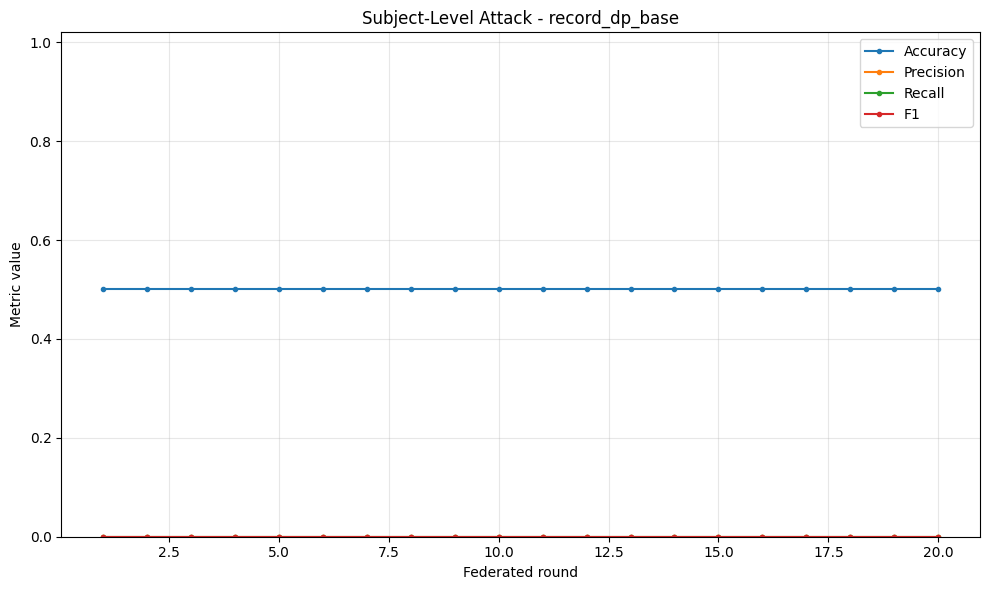

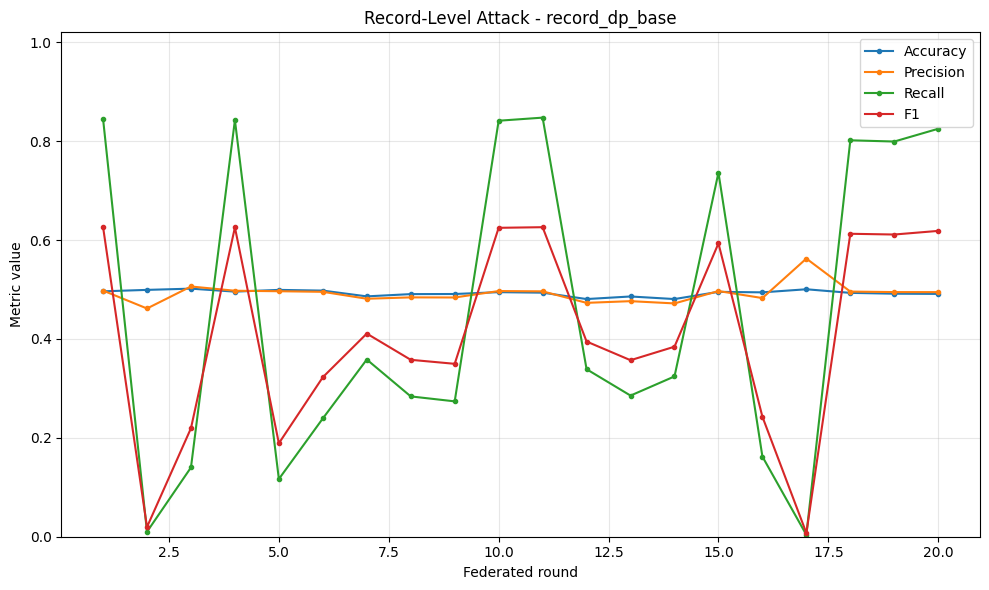

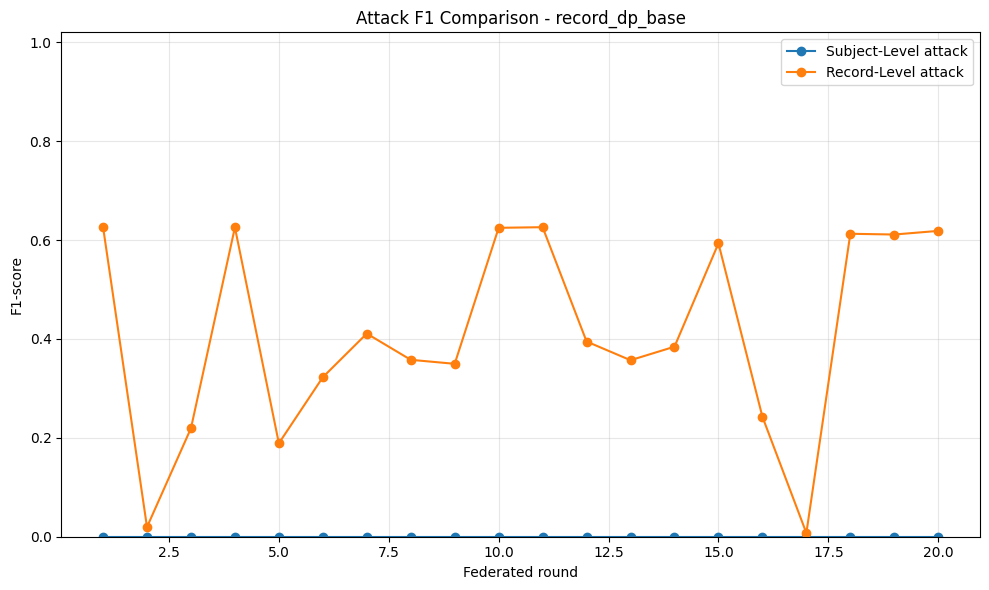

record_dp_base
Final Subject-Level attack
Accuracy: 50.00%
Precision: 0.00%
Recall: 0.00%
F1: 0.00%
ROC-AUC: 0.4995
Confusion matrix:
[[100   0]
 [100   0]]

Final Record-Level attack
Accuracy: 49.10%
Precision: 49.46%
Recall: 82.50%
F1: 61.85%
ROC-AUC: 0.4859
Confusion matrix:
[[ 377 2023]
 [ 420 1980]]


In [ ]:
record_dp_base_attacks = (evaluate_dp_attacks("record_dp_base"))

Attacks: subject_dp_base:   0%|          | 0/21 [00:00<?, ?it/s]

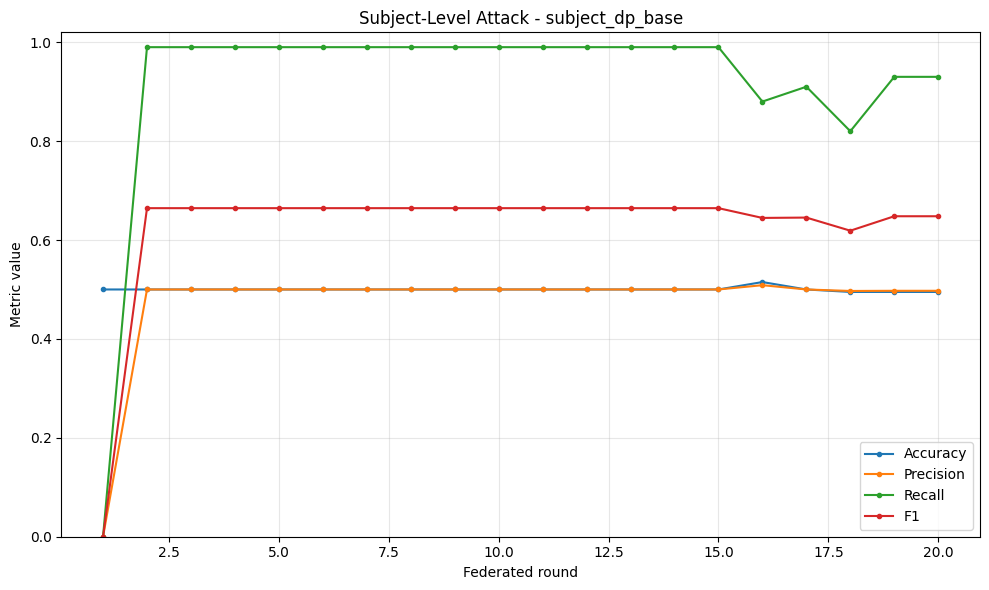

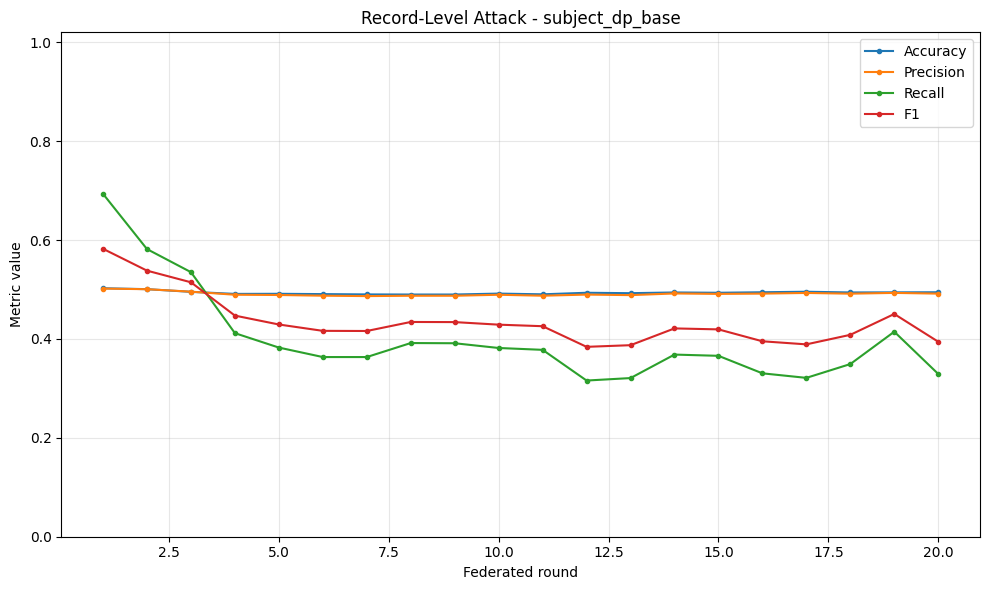

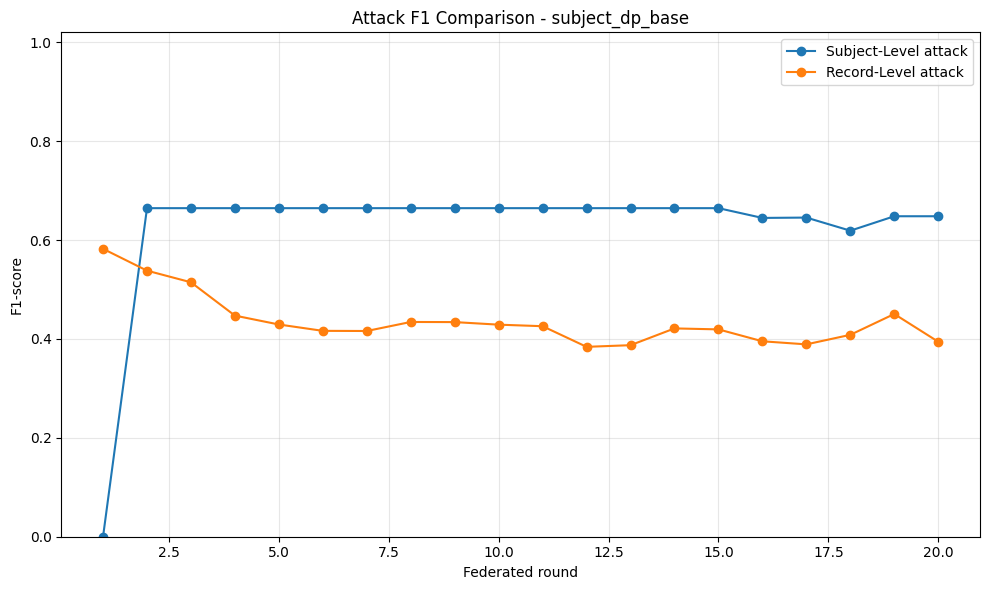

subject_dp_base
Final Subject-Level attack
Accuracy: 49.50%
Precision: 49.73%
Recall: 93.00%
F1: 64.81%
ROC-AUC: 0.5228
Confusion matrix:
[[ 6 94]
 [ 7 93]]

Final Record-Level attack
Accuracy: 49.44%
Precision: 49.16%
Recall: 32.92%
F1: 39.43%
ROC-AUC: 0.4914
Confusion matrix:
[[1583  817]
 [1610  790]]


In [97]:
subject_dp_base_attacks = (
    evaluate_dp_attacks(
        "subject_dp_base"
    )
)

In [98]:
sigma_x2_summary = (
    train_record_dp_experiment(
        experiment_name="record_dp_sigma_x2",
        rounds=BASE_DP_ROUNDS,
        clipping_norm=RECORD_CLIP_NORM,
        sigma_scale=2.0
    )
)

/usr/local/lib/python3.12/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


record_dp_sigma_x2 Round 1/20:   0%|          | 0/8 [00:00<?, ?it/s]

sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


record_dp_sigma_x2 | Round 01 | Train Acc: 5.01% | Test Acc: 6.98% | Test Loss: 3.7994 | Time: 17.6s


record_dp_sigma_x2 Round 2/20:   0%|          | 0/8 [00:00<?, ?it/s]

...

record_dp_sigma_x2 | Round 18 | Train Acc: 25.21% | Test Acc: 28.66% | Test Loss: 3.5400 | Time: 17.8s


record_dp_sigma_x2 Round 19/20:   0%|          | 0/8 [00:00<?, ?it/s]

record_dp_sigma_x2 | Round 19 | Train Acc: 25.23% | Test Acc: 29.03% | Test Loss: 3.5096 | Time: 17.8s


record_dp_sigma_x2 Round 20/20:   0%|          | 0/8 [00:00<?, ?it/s]

record_dp_sigma_x2 | Round 20 | Train Acc: 27.15% | Test Acc: 31.38% | Test Loss: 3.4755 | Time: 17.8s
{
  "experiment": "record_dp_sigma_x2",
  "defense": "record_level_dp_sgd",
  "rounds": 20,
  "target_delta": 1e-05,
  "clipping_norm": 1.0,
  "sigma_scale": 2.0,
  "sigma_mean": 3.37890625,
  "sigma_min": 3.37890625,
  "sigma_max": 3.37890625,
  "noise_std_mean": 3.37890625,
  "epsilon_mean": 1.6401293631470333,
  "epsilon_max": 1.6401293631470333,
  "final_test_loss": 3.4754882602691652,
  "final_test_accuracy": 0.3138,
  "training_time_seconds": 354.41426849365234
}


Attacks: record_dp_sigma_x2:   0%|          | 0/21 [00:00<?, ?it/s]

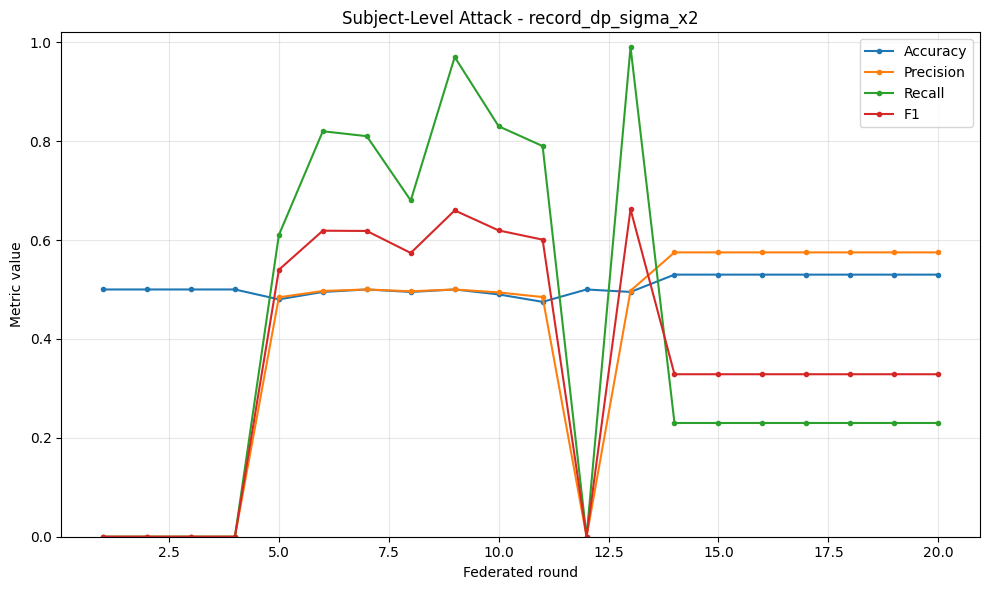

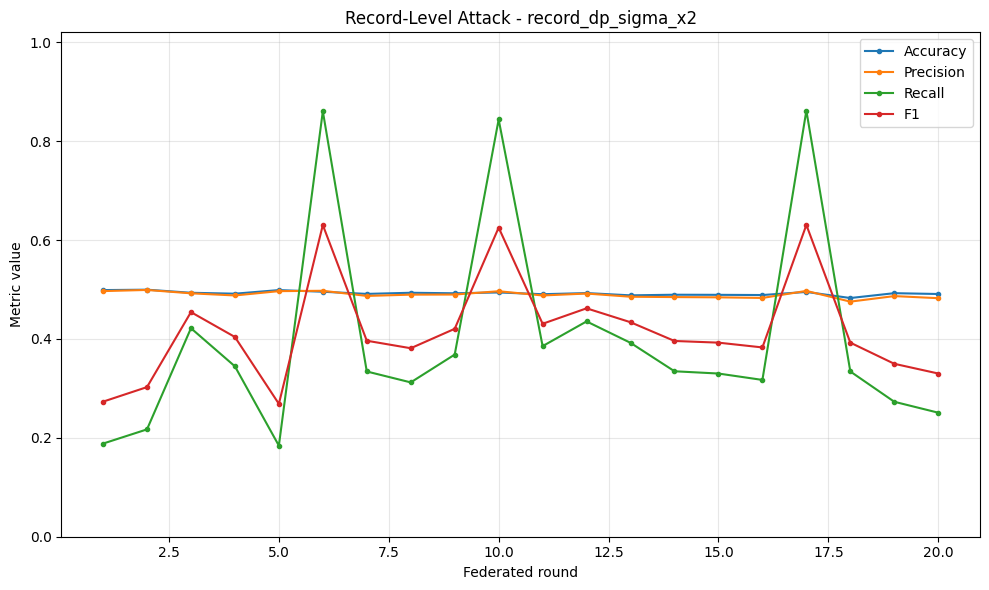

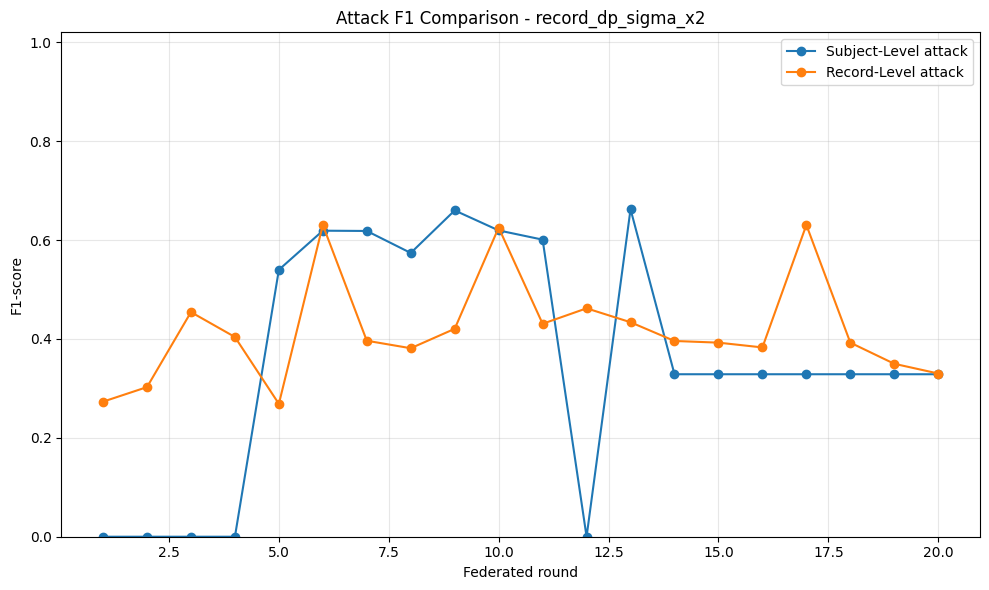

record_dp_sigma_x2
Final Subject-Level attack
Accuracy: 53.00%
Precision: 57.50%
Recall: 23.00%
F1: 32.86%
ROC-AUC: 0.5150
Confusion matrix:
[[83 17]
 [77 23]]

Final Record-Level attack
Accuracy: 49.08%
Precision: 48.24%
Recall: 25.08%
F1: 33.00%
ROC-AUC: 0.4865
Confusion matrix:
[[1754  646]
 [1798  602]]


In [ ]:
sigma_x2_attacks = evaluate_dp_attacks("record_dp_sigma_x2")

In [100]:
clip_half_summary = (
    train_record_dp_experiment(
        experiment_name="record_dp_clip_half",
        rounds=BASE_DP_ROUNDS,
        clipping_norm=(
            RECORD_CLIP_NORM / 2
        ),
        sigma_scale=1.0
    )
)

/usr/local/lib/python3.12/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


record_dp_clip_half Round 1/20:   0%|          | 0/8 [00:00<?, ?it/s]

sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


record_dp_clip_half | Round 01 | Train Acc: 4.92% | Test Acc: 4.97% | Test Loss: 3.7337 | Time: 17.9s


record_dp_clip_half Round 2/20:   0%|          | 0/8 [00:00<?, ?it/s]

...

record_dp_clip_half | Round 18 | Train Acc: 38.13% | Test Acc: 39.86% | Test Loss: 2.5694 | Time: 18.2s


record_dp_clip_half Round 19/20:   0%|          | 0/8 [00:00<?, ?it/s]

record_dp_clip_half | Round 19 | Train Acc: 39.59% | Test Acc: 41.13% | Test Loss: 2.4884 | Time: 17.9s


record_dp_clip_half Round 20/20:   0%|          | 0/8 [00:00<?, ?it/s]

record_dp_clip_half | Round 20 | Train Acc: 40.57% | Test Acc: 42.11% | Test Loss: 2.4284 | Time: 18.0s
{
  "experiment": "record_dp_clip_half",
  "defense": "record_level_dp_sgd",
  "rounds": 20,
  "target_delta": 1e-05,
  "clipping_norm": 0.5,
  "sigma_scale": 1.0,
  "sigma_mean": 1.689453125,
  "sigma_min": 1.689453125,
  "sigma_max": 1.689453125,
  "noise_std_mean": 0.8447265625,
  "epsilon_mean": 3.9907788257864287,
  "epsilon_max": 3.9907788257864287,
  "final_test_loss": 2.4284132320404055,
  "final_test_accuracy": 0.4211,
  "training_time_seconds": 357.0444359779358
}


Attacks: record_dp_clip_half:   0%|          | 0/21 [00:00<?, ?it/s]

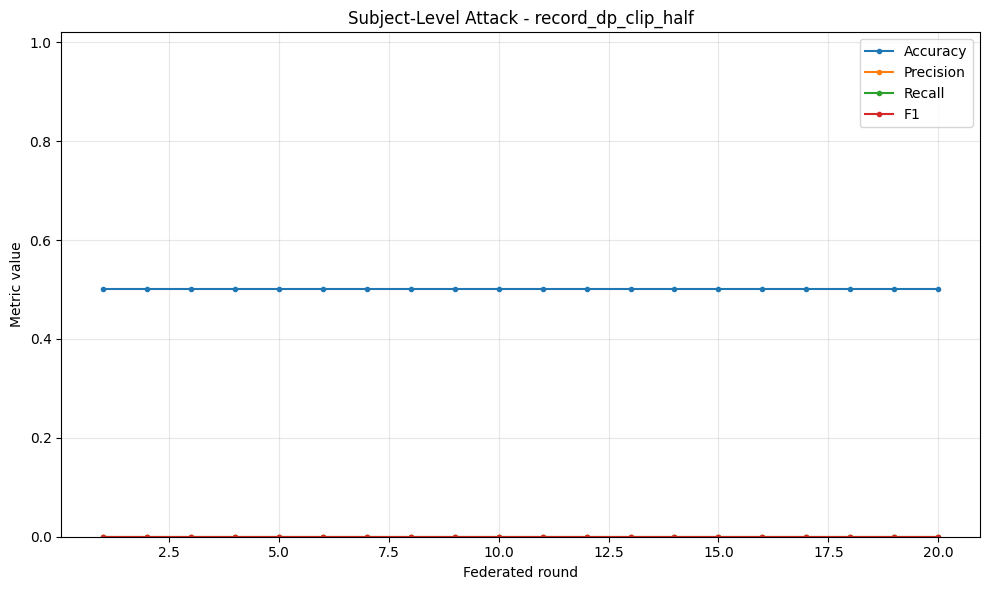

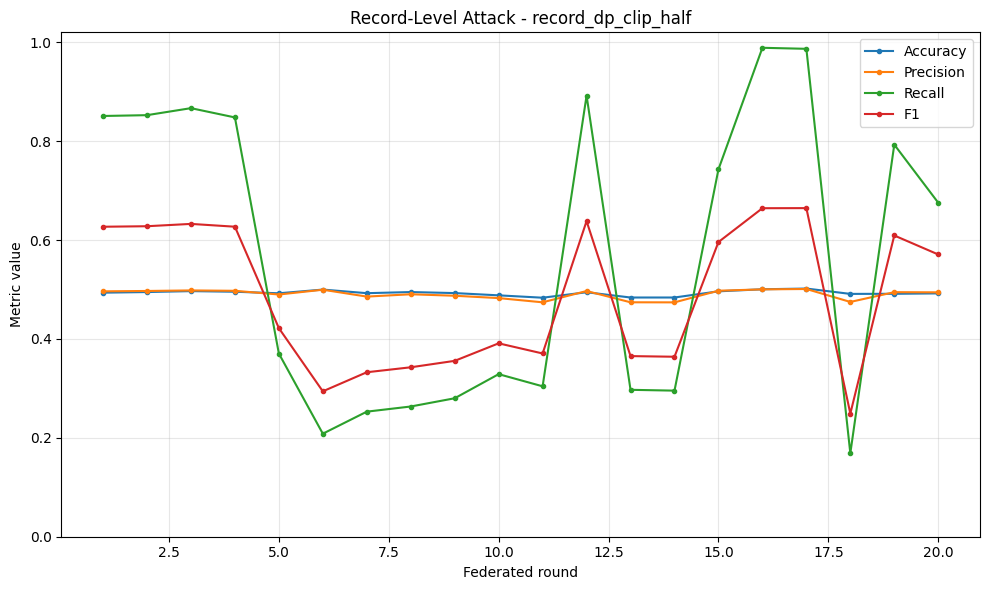

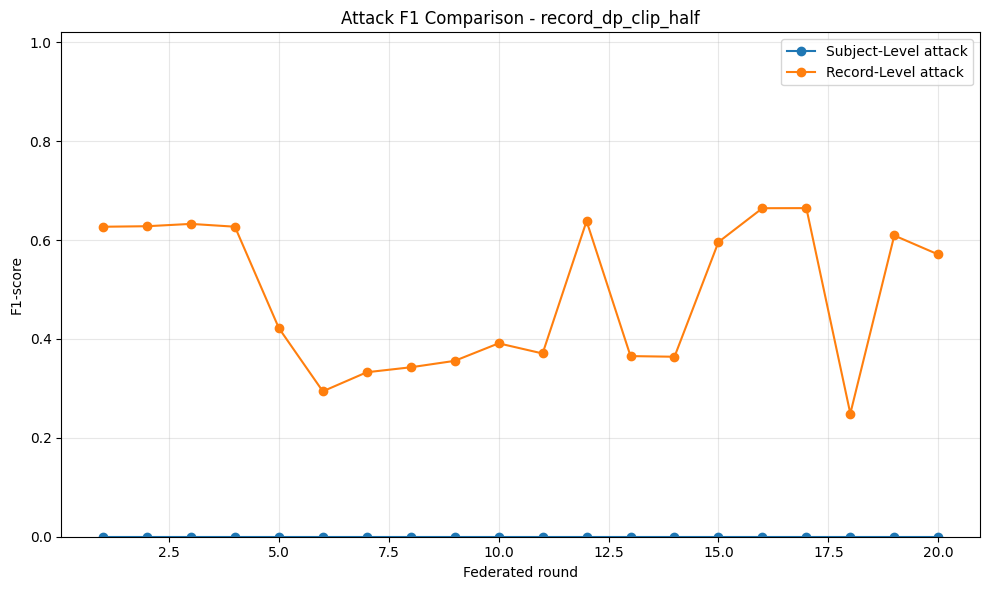

record_dp_clip_half
Final Subject-Level attack
Accuracy: 50.00%
Precision: 0.00%
Recall: 0.00%
F1: 0.00%
ROC-AUC: 0.4558
Confusion matrix:
[[100   0]
 [100   0]]

Final Record-Level attack
Accuracy: 49.21%
Precision: 49.42%
Recall: 67.54%
F1: 57.08%
ROC-AUC: 0.4863
Confusion matrix:
[[ 741 1659]
 [ 779 1621]]


In [ ]:
clip_half_attacks = evaluate_dp_attacks("record_dp_clip_half")

In [102]:
rounds_x2_summary = (
    train_record_dp_experiment(
        experiment_name="record_dp_rounds_x2",
        rounds=2 * BASE_DP_ROUNDS,
        clipping_norm=RECORD_CLIP_NORM,
        sigma_scale=1.0
    )
)

/usr/local/lib/python3.12/dist-packages/opacus/privacy_engine.py:98: UserWarning: Secure RNG turned off. This is perfectly fine for experimentation as it allows for much faster training performance, but remember to turn it on and retrain one last time before production with ``secure_mode`` turned on.
  warnings.warn(


record_dp_rounds_x2 Round 1/40:   0%|          | 0/8 [00:00<?, ?it/s]

sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


record_dp_rounds_x2 | Round 01 | Train Acc: 5.00% | Test Acc: 4.97% | Test Loss: 3.7302 | Time: 17.5s


record_dp_rounds_x2 Round 2/40:   0%|          | 0/8 [00:00<?, ?it/s]

...

record_dp_rounds_x2 | Round 38 | Train Acc: 52.93% | Test Acc: 53.58% | Test Loss: 1.9629 | Time: 18.1s


record_dp_rounds_x2 Round 39/40:   0%|          | 0/8 [00:00<?, ?it/s]

record_dp_rounds_x2 | Round 39 | Train Acc: 53.17% | Test Acc: 54.32% | Test Loss: 1.9355 | Time: 17.8s


record_dp_rounds_x2 Round 40/40:   0%|          | 0/8 [00:00<?, ?it/s]

record_dp_rounds_x2 | Round 40 | Train Acc: 53.80% | Test Acc: 54.55% | Test Loss: 1.9461 | Time: 17.8s
{
  "experiment": "record_dp_rounds_x2",
  "defense": "record_level_dp_sgd",
  "rounds": 40,
  "target_delta": 1e-05,
  "clipping_norm": 1.0,
  "sigma_scale": 1.0,
  "sigma_mean": 1.689453125,
  "sigma_min": 1.689453125,
  "sigma_max": 1.689453125,
  "noise_std_mean": 1.689453125,
  "epsilon_mean": 5.776139079924234,
  "epsilon_max": 5.776139079924234,
  "final_test_loss": 1.9461475540161133,
  "final_test_accuracy": 0.5455,
  "training_time_seconds": 713.7837586402893
}


Attacks: record_dp_rounds_x2:   0%|          | 0/41 [00:00<?, ?it/s]

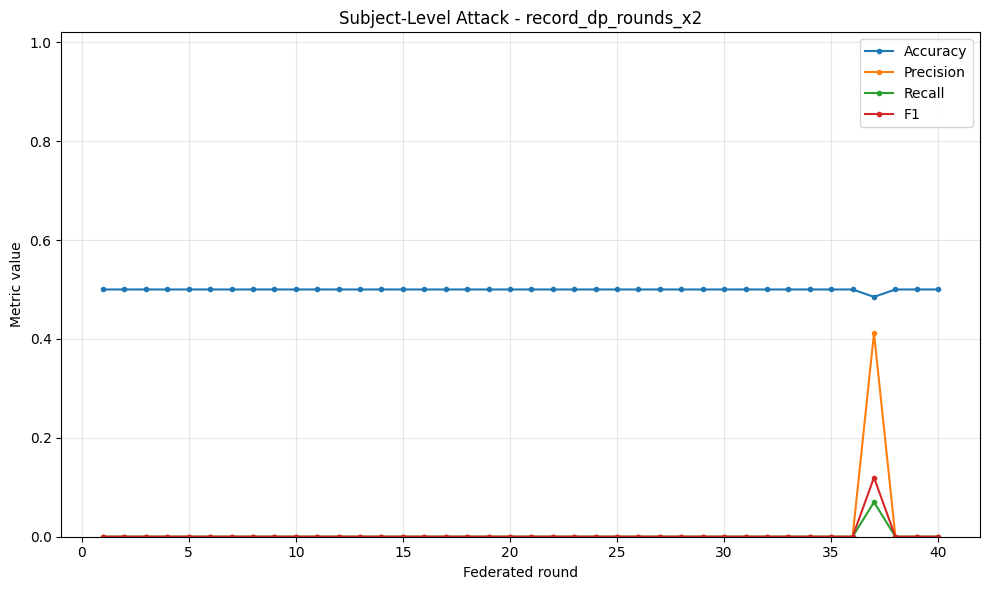

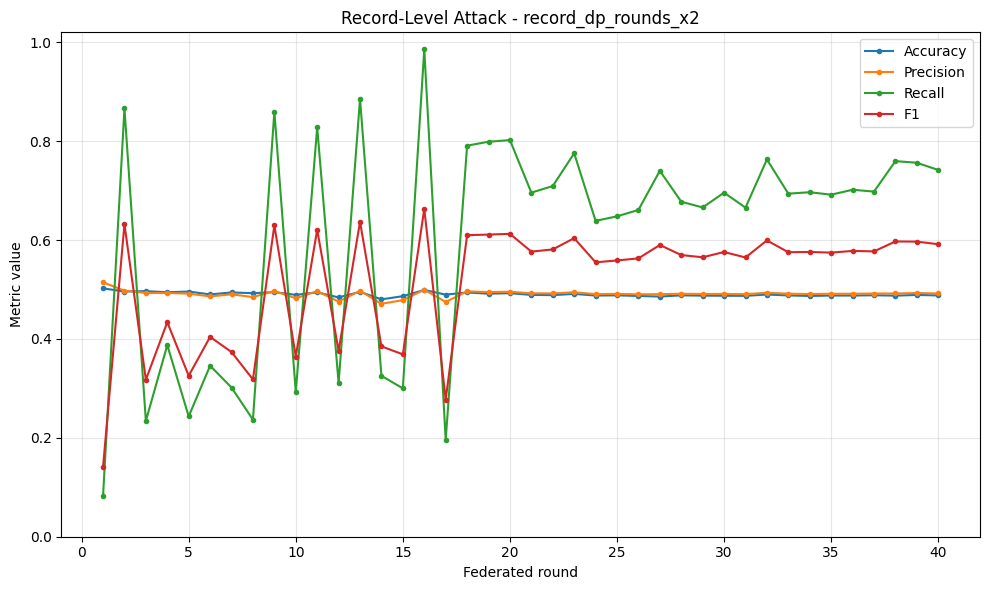

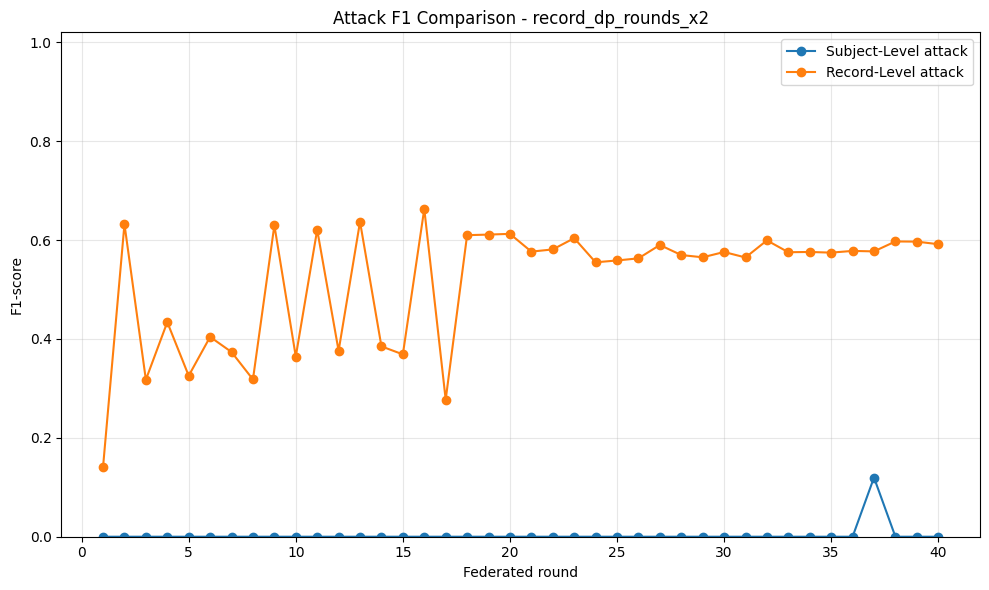

record_dp_rounds_x2
Final Subject-Level attack
Accuracy: 50.00%
Precision: 0.00%
Recall: 0.00%
F1: 0.00%
ROC-AUC: 0.5002
Confusion matrix:
[[100   0]
 [100   0]]

Final Record-Level attack
Accuracy: 48.79%
Precision: 49.20%
Recall: 74.17%
F1: 59.16%
ROC-AUC: 0.4849
Confusion matrix:
[[ 562 1838]
 [ 620 1780]]


In [ ]:
rounds_x2_attacks = evaluate_dp_attacks("record_dp_rounds_x2")

In [ ]:
experiment_names = [
    "record_dp_base",
    "subject_dp_base",
    "record_dp_sigma_x2",
    "record_dp_clip_half",
    "record_dp_rounds_x2"
]

summary_rows = []

for experiment_name in experiment_names:
    training_path = (
        DP_ROOT / experiment_name / "training_summary.json"
    )

    attack_path = (
        DP_ROOT
        / experiment_name
        / "attacks"
        / "attack_summary.json"
    )

    if not training_path.exists() or not attack_path.exists():
        continue

    with open(training_path, "r", encoding="utf-8") as file:
        training_result = json.load(file)

    with open(attack_path, "r", encoding="utf-8") as file:
        attack_result = json.load(file)

    epsilon_value = training_result.get(
        "epsilon_max",
        training_result.get(
            "worst_case_global_epsilon",
            np.nan
        )
    )

    summary_rows.append({
        "experiment": experiment_name,
        "defense": training_result["defense"],
        "rounds": training_result["rounds"],
        "epsilon": epsilon_value,
        "delta": training_result.get(
            "target_delta",
            TARGET_DELTA
        ),
        "sigma_mean": training_result["sigma_mean"],
        "clipping_norm": training_result["clipping_norm"],
        "noise_std_mean": training_result["noise_std_mean"],
        "model_accuracy": training_result["final_test_accuracy"],
        "subject_attack_f1": attack_result["subject_final_f1"],
        "record_attack_f1": attack_result["record_final_f1"],
        "subject_attack_auc": attack_result["subject_final_roc_auc"],
        "record_attack_auc": attack_result["record_final_roc_auc"]
    })

dp_comparison_df = pd.DataFrame(summary_rows)

dp_comparison_df.to_csv(
    DP_ROOT / "dp_comparison_summary.csv",
    index=False
)

print(dp_comparison_df.round(4).to_string(index=False))

         experiment                   defense  rounds  epsilon  delta  sigma_mean  clipping_norm  noise_std_mean  model_accuracy  subject_attack_f1  record_attack_f1  subject_attack_auc  record_attack_auc
     record_dp_base       record_level_dp_sgd      20   3.9908    0.0      1.6895            1.0          1.6895          0.4228             0.0000            0.6185              0.4995             0.4859
    subject_dp_base subject_level_higradavgdp      20   3.9969    0.0      1.5015            1.0          1.5015          0.0548             0.6481            0.3943              0.5228             0.4914
 record_dp_sigma_x2       record_level_dp_sgd      20   1.6401    0.0      3.3789            1.0          3.3789          0.3138             0.3286            0.3300              0.5150             0.4865
record_dp_clip_half       record_level_dp_sgd      20   3.9908    0.0      1.6895            0.5          0.8447          0.4211             0.0000            0.5708              0

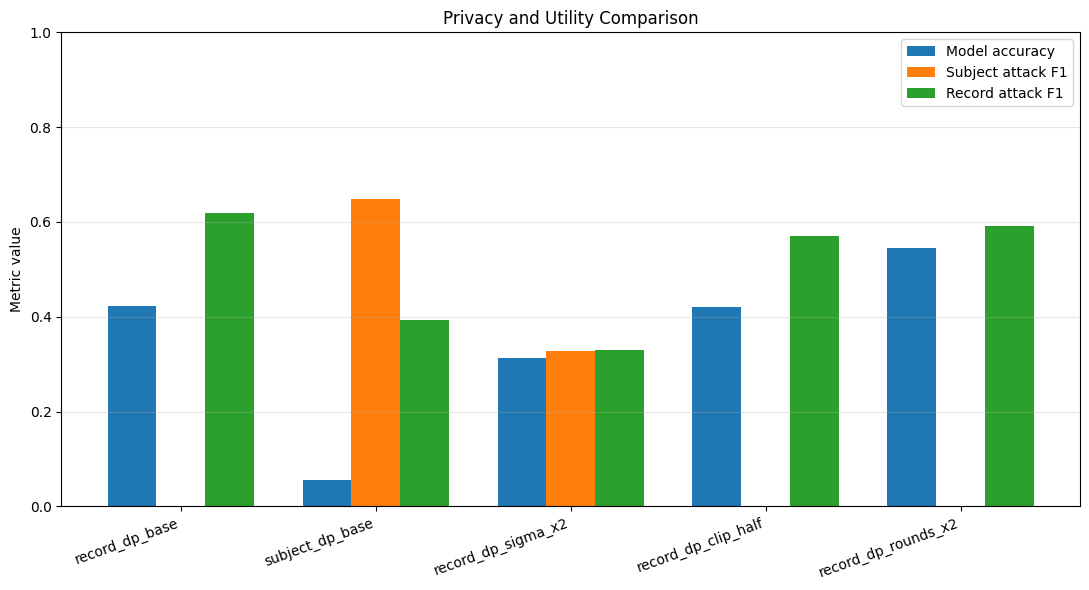

In [ ]:
plot_df = dp_comparison_df.copy()
plt.figure(figsize=(11, 6))
x = np.arange(len(plot_df))
width = 0.25

plt.bar(
    x - width,
    plot_df["model_accuracy"],
    width,
    label="Model accuracy"
)

plt.bar(
    x,
    plot_df["subject_attack_f1"],
    width,
    label="Subject attack F1"
)

plt.bar(
    x + width,
    plot_df["record_attack_f1"],
    width,
    label="Record attack F1"
)

plt.xticks(
    x,
    plot_df["experiment"],
    rotation=20,
    ha="right"
)

plt.ylabel("Metric value")
plt.title("Privacy and Utility Comparison")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    DP_ROOT /
    "privacy_utility_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()